In [3]:
import pandas as pd
import numpy as np

events = pd.read_csv("../data/events.csv")

In [4]:
events.head()

,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [5]:
events.shape

(2756101, 5)

In [6]:
events.columns

Index(['timestamp', 'visitorid', 'event', 'itemid', 'transactionid'], dtype='object')

In [7]:
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          object 
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), object(1)
memory usage: 105.1+ MB


In [8]:
events.head()

,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [9]:
events.tail()

,timestamp,visitorid,event,itemid,transactionid
2756096,1438398785939,591435,view,261427,NaN
2756097,1438399813142,762376,view,115946,NaN
2756098,1438397820527,1251746,view,78144,NaN
2756099,1438398530703,1184451,view,283392,NaN
2756100,1438400163914,199536,view,152913,NaN


In [10]:
events.isnull().sum()

timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
dtype: int64

In [11]:
(events.isnull().sum() / len(events) * 100).round(2)

timestamp         0.00
visitorid         0.00
event             0.00
itemid            0.00
transactionid    99.19
dtype: float64

In [12]:
events["event"].value_counts()

event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64

In [13]:
events["event"].value_counts(normalize=True).mul(100).round(2)

event
view           96.67
addtocart       2.52
transaction     0.81
Name: proportion, dtype: float64

In [14]:
events["visitorid"].nunique()

1407580

In [15]:
events.groupby("event")["visitorid"].nunique()

event
addtocart        37722
transaction      11719
view           1404179
Name: visitorid, dtype: int64

In [16]:
events["itemid"].nunique

<bound method IndexOpsMixin.nunique of 0          355908
1          248676
2          318965
3          253185
4          367447
            ...  
2756096    261427
2756097    115946
2756098     78144
2756099    283392
2756100    152913
Name: itemid, Length: 2756101, dtype: int64>

In [17]:
events["itemid"].value_counts()

itemid
187946    3412
461686    2978
5411      2334
370653    1854
219512    1800
          ... 
103980       1
316294       1
408646       1
206987       1
230235       1
Name: count, Length: 235061, dtype: int64

In [18]:
events.groupby("event")["itemid"].unique()

event
addtocart      [5206, 10572, 255275, 356475, 312728, 63312, 1...
transaction    [356475, 15335, 81345, 150318, 310791, 54058, ...
view           [355908, 248676, 318965, 253185, 367447, 22556...
Name: itemid, dtype: object

In [19]:
events["transactionid"].nunique()

17672

In [20]:
events["transactionid"].notna().sum()

np.int64(22457)

In [21]:
events["timestamp"].dtype

dtype('int64')

In [22]:
events["timestamp"] = pd.to_datetime(events["timestamp"])

In [23]:
events["timestamp"].min()

Timestamp('1970-01-01 00:23:50.622004384')

In [24]:
events["timestamp"].max()

Timestamp('1970-01-01 00:24:02.545187788')

In [25]:
item_properties_part1 = pd.read_csv("../data/item_properties_part1.csv")

In [26]:
item_properties_part1.shape

(10999999, 4)

In [27]:
item_properties_part1.head()

,timestamp,itemid,property,value
0,1435460400000,460429,categoryid,1338
1,1441508400000,206783,888,1116713 960601 n277.200
2,1439089200000,395014,400,n552.000 639502 n720.000 424566
3,1431226800000,59481,790,n15360.000
4,1431831600000,156781,917,828513


In [28]:
item_properties_part1.tail()

,timestamp,itemid,property,value
10999994,1439694000000,86599,categoryid,618
10999995,1435460400000,153032,1066,n1020.000 424566
10999996,1440298800000,421788,888,35975 856003 37346
10999997,1437879600000,159792,400,n552.000 639502 n720.000 424566
10999998,1436065200000,464846,790,n410640.000


In [29]:
item_properties_part1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10999999 entries, 0 to 10999998
Data columns (total 4 columns):
 #   Column     Dtype 
---  ------     ----- 
 0   timestamp  int64 
 1   itemid     int64 
 2   property   object
 3   value      object
dtypes: int64(2), object(2)
memory usage: 335.7+ MB


In [30]:
item_properties_part1.columns

Index(['timestamp', 'itemid', 'property', 'value'], dtype='object')

In [31]:
item_properties_part1.isnull().sum()

timestamp    0
itemid       0
property     0
value        0
dtype: int64

In [32]:
item_properties_part1.isnull().nunique()

timestamp    1
itemid       1
property     1
value        1
dtype: int64

In [33]:
item_properties_part1["property"].nunique()

1097

In [34]:
item_properties_part1["property"].value_counts()

property
888           1629817
790            970800
available      817387
categoryid     426305
6              343207
               ...   
598                 1
244                 1
424                 1
494                 1
712                 1
Name: count, Length: 1097, dtype: int64

In [35]:
item_properties_part1["itemid"].nunique()

417053

In [36]:
item_properties_part1["itemid"].value_counts()

itemid
162893    322
417200    287
89590     279
271520    278
126333    270
         ... 
40400       3
411763      3
60283       3
84445       3
35818       2
Name: count, Length: 417053, dtype: int64

In [37]:
item_properties_part1["timestamp"] = pd.to_datetime(
    item_properties_part1["timestamp"], 
    unit="ms"
)

In [38]:
item_properties_part1["timestamp"].min()

Timestamp('2015-05-10 03:00:00')

In [39]:
item_properties_part1["timestamp"].max()

Timestamp('2015-09-13 03:00:00')

In [40]:
item_properties_part1["value"].nunique()

1231581

In [41]:
item_properties_part1["value"].head(20)

0                                                  1338
1                               1116713 960601 n277.200
2                       n552.000 639502 n720.000 424566
3                                            n15360.000
4                                                828513
5                                                     0
6                                               1121373
7                                                319724
8                                               1330310
9                                       1141052 n48.000
10                               1038400 45956 n504.000
11                      n552.000 639502 n720.000 424566
12                                       1283144 353870
13                                      1026952 1162729
14                                           n21000.000
15                                                    0
16                                            n5400.000
17                                              

In [42]:
item_properties_part1[["property", "value"]].head(20)

,property,value
0,categoryid,1338
1,888,1116713 960601 n277.200
2,400,n552.000 639502 n720.000 424566
3,790,n15360.000
4,917,828513
5,available,0
6,213,1121373
7,6,319724
8,202,1330310
9,451,1141052 n48.000


In [43]:
item_properties_part1["value"].value_counts().head(20)

value
769062                                 833710
0                                      469704
1                                      348216
519769                                 226502
1285872                                226242
679677                                 226102
1116693                                 85354
1297729 n156.000 606827                 65224
664227                                  63768
664227 1305534 664227 463202 664227     52404
n552.000 639502 n720.000 424566         40680
150169 610517                           39789
1115994                                 29810
664227 1305534 664227                   27589
1154859                                 27067
150169 274770 79212                     26663
1037891                                 26384
n12.000                                 25179
1141052 n48.000 140719 553394           23466
1152934 1238769                         23434
Name: count, dtype: int64

In [44]:
item_properties_part2 = pd.read_csv("../data/item_properties_part2.csv")

In [45]:
item_properties_part2.shape

(9275903, 4)

In [46]:
item_properties_part2.columns

Index(['timestamp', 'itemid', 'property', 'value'], dtype='object')

In [47]:
item_properties_part2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9275903 entries, 0 to 9275902
Data columns (total 4 columns):
 #   Column     Dtype 
---  ------     ----- 
 0   timestamp  int64 
 1   itemid     int64 
 2   property   object
 3   value      object
dtypes: int64(2), object(2)
memory usage: 283.1+ MB


In [48]:
item_properties_part2.isnull().sum()

timestamp    0
itemid       0
property     0
value        0
dtype: int64

In [49]:
item_properties_part2["itemid"].nunique()

417053

In [50]:
item_properties_part2["property"].nunique()

1094

In [51]:
item_properties_part2["timestamp"].min()

np.int64(1431226800000)

In [52]:
item_properties_part2["timestamp"].max()

np.int64(1442113200000)

In [53]:
item_properties_part2["timestamp"] = pd.to_datetime(
    item_properties_part2["timestamp"], 
    unit="ms"
)

In [54]:
item_properties_part2["timestamp"].min()

Timestamp('2015-05-10 03:00:00')

In [55]:
item_properties_part2["timestamp"].max()

Timestamp('2015-09-13 03:00:00')

In [56]:
item_properties_part2["property"].value_counts().head(20)

property
888           1370581
790            819716
available      686252
categoryid     361909
6              288264
283            273738
776            262566
364            220146
678            220137
202            205954
112            190951
764            190811
917            190790
159            190551
839            190318
227            159283
698            132568
451            122028
962            110396
663            109482
Name: count, dtype: int64

In [57]:
item_properties_part1["property"].value_counts().head(20)

property
888           1629817
790            970800
available      817387
categoryid     426305
6              343207
283            323681
776            311654
678            261829
364            256340
202            242984
839            226921
159            226502
917            226437
764            226242
112            226102
227            188209
698            157281
451            142388
663            131331
962            128976
Name: count, dtype: int64

In [58]:
item_properties_part1.tail(5)

,timestamp,itemid,property,value
10999994,2015-08-16 03:00:00,86599,categoryid,618
10999995,2015-06-28 03:00:00,153032,1066,n1020.000 424566
10999996,2015-08-23 03:00:00,421788,888,35975 856003 37346
10999997,2015-07-26 03:00:00,159792,400,n552.000 639502 n720.000 424566
10999998,2015-07-05 03:00:00,464846,790,n410640.000


In [59]:
item_properties_part2.tail(5)

,timestamp,itemid,property,value
9275898,2015-06-07 03:00:00,236931,929,n12.000
9275899,2015-08-30 03:00:00,455746,6,150169 639134
9275900,2015-08-16 03:00:00,347565,686,610834
9275901,2015-06-07 03:00:00,287231,867,769062
9275902,2015-09-13 03:00:00,275768,888,888666 n10800.000 746840 1318567


In [60]:
item_properties_part2["value"].value_counts().head(20)

value
769062                                 703537
0                                      393542
1                                      293204
679677                                 190952
1285872                                190811
519769                                 190551
1116693                                 71889
1297729 n156.000 606827                 54912
664227                                  54885
664227 1305534 664227 463202 664227     43841
150169 610517                           33558
n552.000 639502 n720.000 424566         33139
1115994                                 25158
664227 1305534 664227                   24132
1154859                                 22908
150169 274770 79212                     22413
1037891                                 22159
n12.000                                 20796
726612                                  20003
1141052 n48.000 140719 553394           19852
Name: count, dtype: int64

In [61]:
item_properties_part2["value"].nunique()

1075730

In [62]:
item_properties_part2.duplicated().sum()

np.int64(0)

In [63]:
item_properties_part1.duplicated().sum()

np.int64(0)

In [64]:
common_rows = item_properties_part1.merge(
    item_properties_part2,
    on=["timestamp", "itemid", "property", "value"],
    how = "inner"
)

common_rows.shape

(0, 4)

In [65]:
item_properties = pd.concat(
    [item_properties_part1,item_properties_part2],
    ignore_index=True
)

In [66]:
item_properties.shape

(20275902, 4)

In [67]:
item_properties.head()

,timestamp,itemid,property,value
0,2015-06-28 03:00:00,460429,categoryid,1338
1,2015-09-06 03:00:00,206783,888,1116713 960601 n277.200
2,2015-08-09 03:00:00,395014,400,n552.000 639502 n720.000 424566
3,2015-05-10 03:00:00,59481,790,n15360.000
4,2015-05-17 03:00:00,156781,917,828513


In [68]:
item_properties.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20275902 entries, 0 to 20275901
Data columns (total 4 columns):
 #   Column     Dtype         
---  ------     -----         
 0   timestamp  datetime64[ns]
 1   itemid     int64         
 2   property   object        
 3   value      object        
dtypes: datetime64[ns](1), int64(1), object(2)
memory usage: 618.8+ MB


In [69]:
category_tree = pd.read_csv("../data/category_tree.csv")

In [70]:
category_tree.shape

(1669, 2)

In [71]:
category_tree.columns

Index(['categoryid', 'parentid'], dtype='object')

In [72]:
category_tree.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1669 entries, 0 to 1668
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   categoryid  1669 non-null   int64  
 1   parentid    1644 non-null   float64
dtypes: float64(1), int64(1)
memory usage: 26.2 KB


In [73]:
category_tree.isnull().sum()

categoryid     0
parentid      25
dtype: int64

In [74]:
category_tree.head(20)

,categoryid,parentid
0,1016,213.0
1,809,169.0
2,570,9.0
3,1691,885.0
4,536,1691.0
5,231,NaN
6,542,378.0
7,1146,542.0
8,1140,542.0
9,1479,1537.0


In [75]:
category_tree.nunique()

categoryid    1669
parentid       362
dtype: int64

In [76]:
category_tree["categoryid"].value_counts().head(20)

categoryid
1016    1
809     1
570     1
1691    1
536     1
231     1
542     1
1146    1
1140    1
1479    1
83      1
688     1
257     1
1640    1
963     1
412     1
948     1
934     1
148     1
12      1
Name: count, dtype: int64

In [77]:
category_tree["parentid"].value_counts().head(20)

parentid
250.0     31
1009.0    22
362.0     22
351.0     19
1259.0    18
1687.0    17
945.0     15
312.0     15
92.0      13
1482.0    13
893.0     13
540.0     12
593.0     12
131.0     11
1224.0    11
1600.0    10
653.0     10
1490.0    10
587.0     10
381.0     10
Name: count, dtype: int64

In [78]:
category_tree[["categoryid","parentid"]].head(20)

,categoryid,parentid
0,1016,213.0
1,809,169.0
2,570,9.0
3,1691,885.0
4,536,1691.0
5,231,NaN
6,542,378.0
7,1146,542.0
8,1140,542.0
9,1479,1537.0


In [79]:
category_tree[category_tree["parentid"].isnull()]

,categoryid,parentid
5,231,NaN
589,791,NaN
861,1490,NaN
939,431,NaN
1111,755,NaN
1142,378,NaN
1208,1579,NaN
1211,1394,NaN
1322,659,NaN
1329,1057,NaN


In [80]:
category_tree["parentid"].value_counts().head(10)

parentid
250.0     31
1009.0    22
362.0     22
351.0     19
1259.0    18
1687.0    17
945.0     15
312.0     15
92.0      13
1482.0    13
Name: count, dtype: int64

In [81]:
category_tree["categoryid"].isin(
    category_tree["parentid"].dropna()
).sum()

np.int64(362)

In [82]:
"categoryid" in item_properties_part1["property"].values

True

In [83]:
# 1. Find category records

category_rows = item_properties_part1[
    item_properties_part1["property"] == "categoryid"
]

In [84]:
category_rows.head(20)

,timestamp,itemid,property,value
0,2015-06-28 03:00:00,460429,categoryid,1338
140,2015-05-24 03:00:00,281245,categoryid,1277
151,2015-06-28 03:00:00,35575,categoryid,1059
189,2015-07-19 03:00:00,8313,categoryid,1147
197,2015-07-26 03:00:00,55102,categoryid,47
213,2015-05-31 03:00:00,397079,categoryid,619
237,2015-07-12 03:00:00,265036,categoryid,1228
254,2015-07-26 03:00:00,124459,categoryid,1277
310,2015-07-26 03:00:00,350508,categoryid,546
325,2015-08-09 03:00:00,221365,categoryid,1226


In [85]:
# 2. See how many products have category information
category_rows["itemid"].nunique()

229341

In [86]:
# 3. See how many different categories appear
category_rows["value"].nunique()

1196

In [87]:
# 4. Convert category values to numbers
category_values = pd.to_numeric(
    category_rows["value"],
    errors="coerce"
)

In [88]:
# 5. Check whether conversion failed
category_values.isna().sum()

np.int64(0)

In [89]:
category_values.nunique()

1196

In [90]:
# 6. Check how many category IDs exist in category_tree

category_values.isin(
    category_tree["categoryid"]
).mean()

# Completed the raw_data understanding phase

np.float64(0.9997841920690586)

In [91]:
# Building of data Model.

""" events.csv
visitorid · itemid · event · timestamp

Connect using itemid

Combined item properties
itemid · timestamp · property · value
Part 1 + Part 2

Extract categoryid from property/value

category_tree.csv
categoryid · parentid
"""

' events.csv\nvisitorid · itemid · event · timestamp\n\nConnect using itemid\n\nCombined item properties\nitemid · timestamp · property · value\nPart 1 + Part 2\n\nExtract categoryid from property/value\n\ncategory_tree.csv\ncategoryid · parentid\n'

In [92]:
category_rows = item_properties[
    item_properties["property"] == "categoryid"
]

category_rows.head()

,timestamp,itemid,property,value
0,2015-06-28 03:00:00,460429,categoryid,1338
140,2015-05-24 03:00:00,281245,categoryid,1277
151,2015-06-28 03:00:00,35575,categoryid,1059
189,2015-07-19 03:00:00,8313,categoryid,1147
197,2015-07-26 03:00:00,55102,categoryid,47


In [93]:
category_rows[["itemid","timestamp","value"]].head(10)

,itemid,timestamp,value
0,460429,2015-06-28 03:00:00,1338
140,281245,2015-05-24 03:00:00,1277
151,35575,2015-06-28 03:00:00,1059
189,8313,2015-07-19 03:00:00,1147
197,55102,2015-07-26 03:00:00,47
213,397079,2015-05-31 03:00:00,619
237,265036,2015-07-12 03:00:00,1228
254,124459,2015-07-26 03:00:00,1277
310,350508,2015-07-26 03:00:00,546
325,221365,2015-08-09 03:00:00,1226


In [94]:
# Check category coverage
category_values = pd.to_numeric(
    category_rows["value"],
    errors="coerce"
)

print("Category records:", len(category_rows))
print("Unique items:", category_rows["itemid"].nunique())
print("Unique category values:", category_values.nunique())
print("Values that failed numeric conversion:", category_values.isna().sum())

Category records: 788214
Unique items: 417053
Unique category values: 1242
Values that failed numeric conversion: 0


In [95]:
# Validate against the category tree

valid_categories = category_values.isin(
    category_tree["categoryid"]
)

print("Matching records:", valid_categories.sum())
print("Non-matching records:", (~valid_categories).sum())
print("Match percenatge:", round(valid_categories.mean() * 100,2))

""" This checks whether the extracted category values exist in the category hierarchy. 
A non-match is something to investigate, not automatically delete. """

Matching records: 788047
Non-matching records: 167
Match percenatge: 99.98


' This checks whether the extracted category values exist in the category hierarchy. \nA non-match is something to investigate, not automatically delete. '

In [96]:
invalid_category_rows = category_rows[
    ~category_values.isin(category_tree["categoryid"])
]

invalid_category_rows[
    ["timestamp", "itemid", "property", "value"]
].head(20)

,timestamp,itemid,property,value
96253,2015-05-31 03:00:00,221628,categoryid,919
105161,2015-05-10 03:00:00,201300,categoryid,1062
317990,2015-05-31 03:00:00,61880,categoryid,1062
344842,2015-06-14 03:00:00,323806,categoryid,306
387200,2015-06-28 03:00:00,106156,categoryid,306
790827,2015-06-28 03:00:00,345237,categoryid,1446
1279055,2015-05-10 03:00:00,137525,categoryid,1446
1342558,2015-06-28 03:00:00,176558,categoryid,181
1382154,2015-05-31 03:00:00,343744,categoryid,306
1396541,2015-05-10 03:00:00,286140,categoryid,919


In [97]:
category_rows.groupby("itemid")["value"].nunique().value_counts().sort_index()

value
1    393701
2     21373
3      1931
4        48
Name: count, dtype: int64

In [98]:
print(category_values.dtype)
print(category_tree["categoryid"].dtype)

unmatched_values = category_values[
    ~category_values.isin(category_tree["categoryid"])
]

print("Unmatched records:", len(unmatched_values))
print("Distinct unmatched IDs:", unmatched_values.nunique())
print("Unmatched IDs:")
print(unmatched_values.value_counts().head(20))

int64
int64
Unmatched records: 167
Distinct unmatched IDs: 30
Unmatched IDs:
value
306     91
347     10
1062     8
919      8
1446     7
1046     6
181      5
974      3
462      3
554      3
280      2
1158     2
171      2
1319     1
1571     1
1428     1
566      1
1597     1
300      1
930      1
Name: count, dtype: int64


In [99]:
category_counts = category_rows.groupby("itemid")["value"].nunique()

multiple_category_items = category_counts[
    category_counts > 1
]

multiple_category_items.head()

itemid
25     2
94     2
130    2
149    2
168    2
Name: value, dtype: int64

In [100]:
sample_item_id = multiple_category_items.index[0]

category_rows[
    category_rows["itemid"] == sample_item_id
].sort_values("timestamp")


,timestamp,itemid,property,value
7786530,2015-05-10 03:00:00,25,categoryid,1509
8382882,2015-05-17 03:00:00,25,categoryid,1509
8581666,2015-05-24 03:00:00,25,categoryid,1509
8979234,2015-05-31 03:00:00,25,categoryid,1509
7985314,2015-06-07 03:00:00,25,categoryid,1509
8184098,2015-06-14 03:00:00,25,categoryid,1509
8780450,2015-06-28 03:00:00,25,categoryid,1509
9575586,2015-07-05 03:00:00,25,categoryid,1509
9376802,2015-07-12 03:00:00,25,categoryid,1509
9178018,2015-07-19 03:00:00,25,categoryid,1509


In [101]:
#count distinct category values for each item
category_counts = (
    category_rows.groupby("itemid")["value"].nunique()
)

In [102]:
#count items whose category values differ across history

items_with_category_changes = category_counts[category_counts > 1]

print("Total unique items:", category_counts.shape[0])

print(
    "Items with multiple category values:",
    len(items_with_category_changes)
)

print(
    "Percentage of items with multiple categories:",
    round(
        len(items_with_category_changes)
        / len(category_counts) * 100,
        2
    ),
    "%"
)

Total unique items: 417053
Items with multiple category values: 23352
Percentage of items with multiple categories: 5.6 %


In [103]:
#Work with the category history
category_history = category_rows[
    ["timestamp", "itemid", "value"]
].copy()


In [104]:
# Ensure records are ordered by item and time
category_history = category_history.sort_values(
    ["itemid", "timestamp"]
)


In [105]:
#Get the previous category for each item
category_history["previous_category"] = (
    category_history.groupby("itemid")["value"].shift(1)
)

In [106]:
#Keep records where the category differs from its previous value

category_changes = category_history[
    category_history["previous_category"].notna()
    & (
        category_history["value"]
        != category_history["previous_category"]
    )
].copy()

In [107]:
print("Total category records:", len(category_history))
print("Recorded category transitions:", len(category_changes))
print("Items with recorded transitions:", category_changes["itemid"].nunique())

display(category_changes.head(10))

Total category records: 788214
Recorded category transitions: 25619
Items with recorded transitions: 23352


,timestamp,itemid,value,previous_category
10370722,2015-08-16 03:00:00,25,72,1509
8435950,2015-08-23 03:00:00,94,1244,1147
5541224,2015-08-23 03:00:00,130,438,1277
8907514,2015-08-09 03:00:00,149,491,1120
17071854,2015-06-07 03:00:00,168,822,1006
12634876,2015-08-09 03:00:00,181,491,1613
8068842,2015-06-07 03:00:00,216,1404,1635
8834035,2015-08-23 03:00:00,217,637,319
844105,2015-08-23 03:00:00,218,438,1277
5285887,2015-05-24 03:00:00,234,1346,1301


In [108]:
#count category transitions by date
category_changes["change_date"] = (
    category_changes["timestamp"].dt.date
)

changes_by_date = (
    category_changes.groupby("change_date")
    .size()
    .sort_index()
)

display(changes_by_date)

print("Data with most recorded transitions:")
print(changes_by_date.idxmax())

print("Maximum transitions on one date:")
print(changes_by_date.max())

change_date
2015-05-17      26
2015-05-24      66
2015-05-31      25
2015-06-07     476
2015-06-14       2
2015-06-28    1155
2015-07-05    2440
2015-07-12    1306
2015-07-19    1317
2015-07-26     275
2015-08-02      37
2015-08-09    8595
2015-08-16    2394
2015-08-23    5276
2015-08-30     408
2015-09-06    1313
2015-09-13     508
dtype: int64

Data with most recorded transitions:
2015-08-09
Maximum transitions on one date:
8595


In [109]:
#count all property records by timestamp date
item_properties["property_date"] = (
    item_properties["timestamp"].dt.date
)

property_counts_by_date = (
    item_properties.groupby("property_date").size()
)

#compare the two peak dates with overall property activity
peak_dates = [
    pd.Timestamp("2015-08-09").date(),
    pd.Timestamp("2015-08-23").date()
]

print("All property records on peak dates:")

display(property_counts_by_date.reindex(peak_dates))

print("\nCategory transitions on peak dates:")

display(changes_by_date.reindex(peak_dates))

All property records on peak dates:


property_date
2015-08-09    542778
2015-08-23    571339
dtype: int64


Category transitions on peak dates:


change_date
2015-08-09    8595
2015-08-23    5276
dtype: int64

In [110]:
# Examine category transitions on August 9
aug9_changes = category_changes[
    category_changes["change_date"] == pd.Timestamp("2015-08-09").date()
]

# Count how often each old-to-new category pair appears
aug9_pairs = (
    aug9_changes
    .groupby(["previous_category", "value"])
    .agg(
        transition_count=("itemid", "size"),
        unique_items=("itemid", "nunique")
    )
    .sort_values("transition_count", ascending=False)
)

print("Unique products with transitions on August 9:",
      aug9_changes["itemid"].nunique())

print("\nMost frequent category transitions:")
display(aug9_pairs.head(10))

Unique products with transitions on August 9: 8595

Most frequent category transitions:


transition_count  unique_items
previous_category value                                
1613              491                1765          1765
1120              491                1502          1502
546               1114               1179          1179
                  282                 746           746
642               429                 700           700
282               1114                541           541
1228              1085                404           404
1561              360                 234           234
74                449                 205           205
                  572                 188           188

In [111]:
# Start with the top 10 category-transition pairs
top_pairs = aug9_pairs.head(10).reset_index().copy()

# Convert category IDs to numeric values
top_pairs["previous_category"] = pd.to_numeric(
    top_pairs["previous_category"], errors="coerce"
).astype("Int64")

top_pairs["value"] = pd.to_numeric(
    top_pairs["value"], errors="coerce"
).astype("Int64")

# Prepare category hierarchy lookup
category_lookup = category_tree[["categoryid", "parentid"]].copy()

category_lookup["categoryid"] = pd.to_numeric(
    category_lookup["categoryid"], errors="coerce"
).astype("Int64")

# Match the previous category to its parent
top_pairs = top_pairs.merge(
    category_lookup.rename(columns={
        "categoryid": "previous_category",
        "parentid": "previous_parent"
    }),
    on="previous_category",
    how="left"
)

# Match the new category to its parent
top_pairs = top_pairs.merge(
    category_lookup.rename(columns={
        "categoryid": "value",
        "parentid": "new_parent"
    }),
    on="value",
    how="left"
)

display(
    top_pairs[
        [
            "previous_category",
            "value",
            "transition_count",
            "previous_parent",
            "new_parent"
        ]
    ]
)

,previous_category,value,transition_count,previous_parent,new_parent
0,1613,491,1765,250.0,679.0
1,1120,491,1502,250.0,679.0
2,546,1114,1179,250.0,113.0
3,546,282,746,250.0,113.0
4,642,429,700,250.0,113.0
5,282,1114,541,113.0,113.0
6,1228,1085,404,121.0,1228.0
7,1561,360,234,250.0,1174.0
8,74,449,205,250.0,1139.0
9,74,572,188,250.0,1066.0


In [112]:
print("Dataset shape:", events.shape)

print("\nColumn data types:")
print(events.dtypes)

print("\nEvent counts:")
display(events["event"].value_counts())

print("\nUnique visitors:", events["visitorid"].nunique())
print("Unique products:", events["itemid"].nunique())

Dataset shape: (2756101, 5)

Column data types:
timestamp        datetime64[ns]
visitorid                 int64
event                    object
itemid                    int64
transactionid           float64
dtype: object

Event counts:


event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64


Unique visitors: 1407580
Unique products: 235061


In [113]:
# Count distinct visitors for each event type
visitors_by_event = (
    events.groupby("event")["visitorid"]
    .nunique()
    .sort_values(ascending=False)
)

print("Unique visitors by event:")
display(visitors_by_event)

Unique visitors by event:


event
view           1404179
addtocart        37722
transaction      11719
Name: visitorid, dtype: int64

In [114]:
total_visitors = events["visitorid"].nunique()

visitor_percentages = (
    visitors_by_event / total_visitors * 100
).round(2)

print("Percentage of all unique visitors by event:")
display(visitor_percentages)

Percentage of all unique visitors by event:


event
view           99.76
addtocart       2.68
transaction     0.83
Name: visitorid, dtype: float64

In [115]:
# Sort events chronologically for each visitor
events_sorted = events.sort_values(
    ["visitorid", "timestamp"]
).copy()

# Find the first timestamp for each event type per visitor
visitor_funnel = (
    events_sorted
    .pivot_table(
        index="visitorid",
        columns="event",
        values="timestamp",
        aggfunc="min"
    )
    .reset_index()
)

# Check whether each stage occurred
visitor_funnel["has_view"] = visitor_funnel["view"].notna()
visitor_funnel["has_cart"] = visitor_funnel["addtocart"].notna()
visitor_funnel["has_transaction"] = (
    visitor_funnel["transaction"].notna()
)

# Check whether cart occurred after a view
visitor_funnel["view_then_cart"] = (
    visitor_funnel["view"].notna()
    & visitor_funnel["addtocart"].notna()
    & (
        visitor_funnel["addtocart"]
        >= visitor_funnel["view"]
    )
)

# Check whether transaction occurred after cart, following a view
visitor_funnel["ordered_purchase"] = (
    visitor_funnel["view_then_cart"]
    & visitor_funnel["transaction"].notna()
    & (
        visitor_funnel["transaction"]
        >= visitor_funnel["addtocart"]
    )
)

print("Visitors with a view:", visitor_funnel["has_view"].sum())
print("Visitors with view followed by cart:",
      visitor_funnel["view_then_cart"].sum())
print("Visitors with view, cart, then transaction:",
      visitor_funnel["ordered_purchase"].sum())

Visitors with a view: 1404179
Visitors with view followed by cart: 32272
Visitors with view, cart, then transaction: 9682


In [116]:
viewers = visitor_funnel["has_view"].sum()
view_to_cart = visitor_funnel["view_then_cart"].sum()
ordered_purchases = visitor_funnel["ordered_purchase"].sum()

cart_to_purchase_rate = (
    ordered_purchases / view_to_cart * 100
    if view_to_cart else 0
)

funnel_metrics = pd.DataFrame({
    "Stage": [
        "View",
        "View → Cart",
        "View → Cart → Transaction"
    ],
    "Visitors": [
        viewers,
        view_to_cart,
        ordered_purchases
    ],
    "Conversion_Rate_Percent": [
        100,
        view_to_cart / viewers * 100,
        ordered_purchases / viewers * 100
    ]
})

display(funnel_metrics.round(2))

print(
    "Cart-to-purchase conversion:",
    round(cart_to_purchase_rate, 2),
    "%"
)

,Stage,Visitors,Conversion_Rate_Percent
0,View,1404179,100.00
1,View → Cart,32272,2.30
2,View → Cart → Transaction,9682,0.69


Cart-to-purchase conversion: 30.0 %


In [117]:
# Sort events chronologically for each visitor
events_sorted = events.sort_values(
    ["visitorid", "timestamp"]
).copy()

# Calculate the time gap from the previous event
events_sorted["previous_timestamp"] = (
    events_sorted.groupby("visitorid")["timestamp"].shift(1)
)

events_sorted["gap_minutes"] = (
    events_sorted["timestamp"]
    - events_sorted["previous_timestamp"]
).dt.total_seconds() / 60

# Inspect the distribution of gaps
display(events_sorted["gap_minutes"].describe())

# Check how many gaps exceed 30 minutes
print(
    "Gaps over 30 minutes:",
    (events_sorted["gap_minutes"] > 30).sum()
)

print(
    "Percentage of consecutive-event gaps over 30 minutes:",
    round(
        (events_sorted["gap_minutes"] > 30).mean() * 100,
        2
    ),
    "%"
)

count    1.348521e+06
mean     3.570517e-03
std      1.506602e-02
min      0.000000e+00
25%      6.372167e-07
50%      2.273467e-06
75%      4.082982e-05
max      1.964575e-01
Name: gap_minutes, dtype: float64

Gaps over 30 minutes: 0
Percentage of consecutive-event gaps over 30 minutes: 0.0 %


In [118]:
# Check timestamp type and date range
print("Timestamp data type:", events["timestamp"].dtype)
print("Earliest event:", events["timestamp"].min())
print("Latest event:", events["timestamp"].max())

# Inspect the largest calculated gaps
largest_gaps = events_sorted.nlargest(
    10, "gap_minutes"
)

display(
    largest_gaps[
        [
            "visitorid",
            "previous_timestamp",
            "timestamp",
            "gap_minutes",
            "event"
        ]
    ]
)

Timestamp data type: datetime64[ns]
Earliest event: 1970-01-01 00:23:50.622004384
Latest event: 1970-01-01 00:24:02.545187788


,visitorid,previous_timestamp,timestamp,gap_minutes,event
1456702,35852,1970-01-01 00:23:50.754061469,1970-01-01 00:24:02.541512487,0.196458,view
1446412,147749,1970-01-01 00:23:50.683624408,1970-01-01 00:24:02.436610946,0.195883,view
1456020,228468,1970-01-01 00:23:50.863641839,1970-01-01 00:24:02.525591865,0.194366,view
1441236,243592,1970-01-01 00:23:50.713169917,1970-01-01 00:24:02.352882196,0.193995,view
1457639,593446,1970-01-01 00:23:50.924817945,1970-01-01 00:24:02.528565686,0.193396,view
1437125,608895,1970-01-01 00:23:50.775400802,1970-01-01 00:24:02.376282462,0.193348,view
1439979,70725,1970-01-01 00:23:50.703422555,1970-01-01 00:24:02.303818385,0.193340,view
1452082,506412,1970-01-01 00:23:50.807603515,1970-01-01 00:24:02.387381643,0.192996,view
1431639,597960,1970-01-01 00:23:50.800415368,1970-01-01 00:24:02.376945644,0.192942,view
1450805,321238,1970-01-01 00:23:50.846105727,1970-01-01 00:24:02.421764175,0.192928,view


In [119]:
# Inspect the current timestamp values
print(events["timestamp"].head())

# Check the timestamp column in your original CSV
events_raw = pd.read_csv(
    "../data/events.csv",
    nrows=5
)

display(events_raw)
print(events_raw["timestamp"].dtype)

0   1970-01-01 00:23:53.221332117
1   1970-01-01 00:23:53.224214164
2   1970-01-01 00:23:53.221999827
3   1970-01-01 00:23:53.221955914
4   1970-01-01 00:23:53.221337106
Name: timestamp, dtype: datetime64[ns]


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


int64


In [120]:
events_raw = pd.read_csv("../data/events.csv")

events_raw["timestamp"] = pd.to_datetime(
    events_raw["timestamp"],
    unit="ms"
)

print(events_raw["timestamp"].min())
print(events_raw["timestamp"].max())

2015-05-03 03:00:04.384000
2015-09-18 02:59:47.788000


In [121]:
# Update events using the correctly converted timestamps
events["timestamp"] = events_raw["timestamp"]

print("Earliest event:", events["timestamp"].min())
print("Latest event:", events["timestamp"].max())

Earliest event: 2015-05-03 03:00:04.384000
Latest event: 2015-09-18 02:59:47.788000


In [122]:
# Sort events chronologically for each visitor
events_sorted = events.sort_values(
    ["visitorid", "timestamp"]
).copy()

# Calculate the time since the previous event
events_sorted["previous_timestamp"] = (
    events_sorted.groupby("visitorid")["timestamp"].shift(1)
)

events_sorted["gap_minutes"] = (
    events_sorted["timestamp"]
    - events_sorted["previous_timestamp"]
).dt.total_seconds() / 60

# Inspect the gap distribution
display(events_sorted["gap_minutes"].describe())

print(
    "Gaps over 30 minutes:",
    (events_sorted["gap_minutes"] > 30).sum()
)

print(
    "Percentage of gaps over 30 minutes:",
    round((events_sorted["gap_minutes"] > 30).mean() * 100, 2),
    "%"
)

count    1.348521e+06
mean     3.570517e+03
std      1.506602e+04
min      0.000000e+00
25%      6.372167e-01
50%      2.273467e+00
75%      4.082982e+01
max      1.964575e+05
Name: gap_minutes, dtype: float64

Gaps over 30 minutes: 354095
Percentage of gaps over 30 minutes: 12.85 %


In [123]:
# Work from events sorted by visitor and timestamp
events_sorted = events.sort_values(
    ["visitorid", "timestamp"]
).copy()

# Calculate the time gap between consecutive events
events_sorted["gap_minutes"] = (
    events_sorted.groupby("visitorid")["timestamp"]
    .diff()
    .dt.total_seconds()
    .div(60)
)

# Start a new session at the first event or after a gap over 30 minutes
events_sorted["new_session"] = (
    events_sorted["gap_minutes"].isna()
    | (events_sorted["gap_minutes"] > 30)
)

# Number sessions separately for each visitor, starting at 1
events_sorted["session_number"] = (
    events_sorted.groupby("visitorid")["new_session"]
    .cumsum()
    .astype(int)
)

# Summarize the sessions
total_sessions = events_sorted[
    ["visitorid", "session_number"]
].drop_duplicates().shape[0]

print("Total sessions:", total_sessions)
print("Unique visitors:", events_sorted["visitorid"].nunique())
print("Events assigned to sessions:", len(events_sorted))

print("\nEvents per session:")
display(
    events_sorted.groupby(
        ["visitorid", "session_number"]
    ).size().describe()
)

Total sessions: 1761675
Unique visitors: 1407580
Events assigned to sessions: 2756101

Events per session:


count    1.761675e+06
mean     1.564478e+00
std      2.599988e+00
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      4.170000e+02
dtype: float64

In [124]:
# Get the first timestamp for each event type within each session
session_events = (
    events_sorted
    .pivot_table(
        index=["visitorid", "session_number"],
        columns="event",
        values="timestamp",
        aggfunc="min"
    )
    .reset_index()
)

# Check whether each session contains each event type
session_events["has_view"] = session_events["view"].notna()
session_events["has_cart"] = session_events["addtocart"].notna()
session_events["has_transaction"] = (
    session_events["transaction"].notna()
)

# Check view followed by cart
session_events["view_then_cart"] = (
    session_events["view"].notna()
    & session_events["addtocart"].notna()
    & (
        session_events["addtocart"]
        >= session_events["view"]
    )
)

# Check view, then cart, then transaction
session_events["ordered_purchase"] = (
    session_events["view_then_cart"]
    & session_events["transaction"].notna()
    & (
        session_events["transaction"]
        >= session_events["addtocart"]
    )
)

# Summarize session-level funnel
total_sessions = len(session_events)
view_sessions = session_events["has_view"].sum()
cart_sessions = session_events["view_then_cart"].sum()
purchase_sessions = session_events["ordered_purchase"].sum()

print("Total sessions:", total_sessions)
print("Sessions with a view:", view_sessions)
print("Sessions with view followed by cart:", cart_sessions)
print("Sessions with view, cart, then transaction:", purchase_sessions)

print(
    "View-to-cart rate:",
    round(cart_sessions / view_sessions * 100, 2), "%"
    if view_sessions else "N/A"
)

print(
    "View-to-purchase rate:",
    round(purchase_sessions / view_sessions * 100, 2), "%"
    if view_sessions else "N/A"
)

Total sessions: 1761675
Sessions with a view: 1755781
Sessions with view followed by cart: 35832
Sessions with view, cart, then transaction: 10411
View-to-cart rate: 2.04 %
View-to-purchase rate: 0.59 %


In [125]:
# Sort events chronologically within each session
session_data = events_sorted.sort_values(
    ["visitorid", "session_number", "timestamp"]
).copy()

session_keys = ["visitorid", "session_number"]

# Has a view occurred by this event?
session_data["seen_view"] = (
    session_data["event"].eq("view")
    .groupby(
        [session_data["visitorid"], session_data["session_number"]]
    )
    .cummax()
)

# Does this event represent a cart action after a view?
session_data["cart_after_view"] = (
    session_data["event"].eq("addtocart")
    & session_data["seen_view"]
)

# Has a qualifying cart action occurred by this event?
session_data["seen_cart_after_view"] = (
    session_data["cart_after_view"]
    .groupby(
        [session_data["visitorid"], session_data["session_number"]]
    )
    .cummax()
)

# Does a transaction occur after a view and a cart action?
session_data["purchase_after_cart"] = (
    session_data["event"].eq("transaction")
    & session_data["seen_cart_after_view"]
)

# Summarize each session
sequence_funnel = (
    session_data.groupby(session_keys)
    .agg(
        has_view=("seen_view", "max"),
        has_view_then_cart=("cart_after_view", "max"),
        has_ordered_purchase=("purchase_after_cart", "max")
    )
)

print("Sessions with a view:", sequence_funnel["has_view"].sum())
print(
    "Sessions with view then cart:",
    sequence_funnel["has_view_then_cart"].sum()
)
print(
    "Sessions with view, cart, then transaction:",
    sequence_funnel["has_ordered_purchase"].sum()
)

Sessions with a view: 1755781
Sessions with view then cart: 36675
Sessions with view, cart, then transaction: 10721


In [126]:
# Summarize event counts by product
product_metrics = (
    events.groupby("itemid")
    .agg(
        views=("event", lambda x: (x == "view").sum()),
        add_to_cart=("event", lambda x: (x == "addtocart").sum()),
        transactions=("event", lambda x: (x == "transaction").sum())
    )
    .reset_index()
)

# Keep products with at least 100 views to avoid very small samples
high_view_products = product_metrics[
    product_metrics["views"] >= 100
].copy()

# Calculate add-to-cart rate per view
high_view_products["cart_rate_per_view"] = (
    high_view_products["add_to_cart"]
    / high_view_products["views"]
    * 100
)

# Sort by highest view volume, then lowest cart rate
high_view_products = high_view_products.sort_values(
    ["views", "cart_rate_per_view"],
    ascending=[False, True]
)

print("Products with at least 100 views:", len(high_view_products))

display(
    high_view_products[
        ["itemid", "views", "add_to_cart", "transactions", "cart_rate_per_view"]
    ].head(15)
)

Products with at least 100 views: 3984


,itemid,views,add_to_cart,transactions,cart_rate_per_view
94720,187946,3410,2,0,0.058651
232496,461686,2539,306,133,12.051989
2719,5411,2325,9,0,0.387097
186716,370653,1854,0,0,0.000000
110536,219512,1740,48,12,2.758621
150148,298009,1642,0,0,0.000000
49024,96924,1633,0,0,0.000000
156023,309778,1565,48,15,3.067093
129504,257040,1531,89,27,5.813194
193605,384302,1528,65,15,4.253927


In [127]:
# Use products with at least 500 views for this comparison
product_shortlist = product_metrics[
    product_metrics["views"] >= 500
].copy()

# Calculate event rates per view
product_shortlist["cart_rate_per_view"] = (
    product_shortlist["add_to_cart"]
    / product_shortlist["views"]
    * 100
)

product_shortlist["transaction_rate_per_view"] = (
    product_shortlist["transactions"]
    / product_shortlist["views"]
    * 100
)

# Rank products with the lowest cart rate first
product_shortlist = product_shortlist.sort_values(
    ["cart_rate_per_view", "views"],
    ascending=[True, False]
)

print("Products with at least 500 views:", len(product_shortlist))

display(
    product_shortlist[
        [
            "itemid",
            "views",
            "add_to_cart",
            "transactions",
            "cart_rate_per_view",
            "transaction_rate_per_view"
        ]
    ].head(20).round(2)
)

Products with at least 500 views: 147


,itemid,views,add_to_cart,transactions,cart_rate_per_view,transaction_rate_per_view
186716,370653,1854,0,0,0.0,0.0
150148,298009,1642,0,0,0.0,0.0
49024,96924,1633,0,0,0.0,0.0
169261,335975,1428,0,0,0.0,0.0
76432,151444,1230,0,0,0.0,0.0
218935,434782,1069,0,0,0.0,0.0
46393,91755,1024,0,0,0.0,0.0
51710,102306,1013,0,0,0.0,0.0
14652,29100,982,0,0,0.0,0.0
113669,225778,768,0,0,0.0,0.0


In [128]:

# Keep products that received at least 500 views
product_shortlist = product_metrics[
    product_metrics["views"] >= 500
].copy()

# Calculate add-to-cart rate per view
product_shortlist["cart_rate_per_view"] = (
    product_shortlist["add_to_cart"]
    / product_shortlist["views"] * 100
)

# Calculate transaction rate per view
product_shortlist["transaction_rate_per_view"] = (
    product_shortlist["transactions"]
    / product_shortlist["views"] * 100
)

# Show products with the lowest cart rates first
product_shortlist = product_shortlist.sort_values(
    ["cart_rate_per_view", "views"],
    ascending=[True, False]
)

product_shortlist.head(15)


,itemid,views,add_to_cart,transactions,cart_rate_per_view,transaction_rate_per_view
186716,370653,1854,0,0,0.0,0.0
150148,298009,1642,0,0,0.0,0.0
49024,96924,1633,0,0,0.0,0.0
169261,335975,1428,0,0,0.0,0.0
76432,151444,1230,0,0,0.0,0.0
218935,434782,1069,0,0,0.0,0.0
46393,91755,1024,0,0,0.0,0.0
51710,102306,1013,0,0,0.0,0.0
14652,29100,982,0,0,0.0,0.0
113669,225778,768,0,0,0.0,0.0


In [129]:

print(
    product_shortlist[
        [
            "itemid",
            "views",
            "add_to_cart",
            "transactions",
            "cart_rate_per_view",
            "transaction_rate_per_view"
        ]
    ].head(15).to_string(index=False)
)


 itemid  views  add_to_cart  transactions  cart_rate_per_view  transaction_rate_per_view
 370653   1854            0             0                 0.0                        0.0
 298009   1642            0             0                 0.0                        0.0
  96924   1633            0             0                 0.0                        0.0
 335975   1428            0             0                 0.0                        0.0
 151444   1230            0             0                 0.0                        0.0
 434782   1069            0             0                 0.0                        0.0
  91755   1024            0             0                 0.0                        0.0
 102306   1013            0             0                 0.0                        0.0
  29100    982            0             0                 0.0                        0.0
 225778    768            0             0                 0.0                        0.0
 109618    764       

In [130]:

# Select the 15 products in our current shortlist
low_cart_item_ids = product_shortlist.head(15)["itemid"]

# Find historical category records for these products
low_cart_categories = category_rows[
    category_rows["itemid"].isin(low_cart_item_ids)
]

# Display the available category records
low_cart_categories[
    ["itemid", "timestamp", "value"]
].sort_values(
    ["itemid", "timestamp"]
).head(30)


,itemid,timestamp,value
12930056,91755,2015-05-10 03:00:00,48
11043102,96924,2015-05-10 03:00:00,56
18272295,102306,2015-05-10 03:00:00,499
3430188,109618,2015-05-31 03:00:00,921
18990777,151444,2015-05-10 03:00:00,656
19410488,209994,2015-06-07 03:00:00,35
13650094,225778,2015-06-07 03:00:00,656
12553885,232509,2015-06-28 03:00:00,64
8397871,298009,2015-05-10 03:00:00,529
17627309,335975,2015-06-28 03:00:00,48


In [131]:

category_summary = (
    low_cart_categories
    .groupby("itemid")
    .agg(
        category_record_count=("value", "size"),
        distinct_categories=("value", "nunique"),
        first_record=("timestamp", "min"),
        last_record=("timestamp", "max")
    )
    .reset_index()
)

category_summary = category_summary.sort_values(
    ["distinct_categories", "category_record_count"],
    ascending=[False, False]
)

category_summary


,itemid,category_record_count,distinct_categories,first_record,last_record
10,359491,18,2,2015-05-10 03:00:00,2015-09-13 03:00:00
0,91755,1,1,2015-05-10 03:00:00,2015-05-10 03:00:00
1,96924,1,1,2015-05-10 03:00:00,2015-05-10 03:00:00
2,102306,1,1,2015-05-10 03:00:00,2015-05-10 03:00:00
3,109618,1,1,2015-05-31 03:00:00,2015-05-31 03:00:00
4,151444,1,1,2015-05-10 03:00:00,2015-05-10 03:00:00
5,209994,1,1,2015-06-07 03:00:00,2015-06-07 03:00:00
6,225778,1,1,2015-06-07 03:00:00,2015-06-07 03:00:00
7,232509,1,1,2015-06-28 03:00:00,2015-06-28 03:00:00
8,298009,1,1,2015-05-10 03:00:00,2015-05-10 03:00:00


In [132]:
# Compare the 15 shortlisted products with products
# that have category records
shortlisted_ids = set(product_shortlist.head(15)["itemid"])
category_ids = set(low_cart_categories["itemid"])

print("Shortlisted products:", len(shortlisted_ids))
print("Products with category records:", len(shortlisted_ids & category_ids))
print("Products without category records:", sorted(shortlisted_ids - category_ids))

Shortlisted products: 15
Products with category records: 14
Products without category records: [29100]


In [133]:
# Inspect all available property records for item 29100
item_29100_properties = item_properties[
    item_properties["itemid"] == 29100
]

print("Total property records:", len(item_29100_properties))
print(
    item_29100_properties["property"]
    .value_counts()
    .head(15)
)

item_29100_properties.head(10)


Total property records: 0
Series([], Name: count, dtype: int64)


,timestamp,itemid,property,value,property_date


In [134]:
print(
    "Item 29100 in part 1:",
    (item_properties_part1["itemid"] == 29100).any()
)

print(
    "Item 29100 in part 2:",
    (item_properties_part2["itemid"] == 29100).any()
)

Item 29100 in part 1: False
Item 29100 in part 2: False


In [135]:
# Focus on products with at least 500 views
products_500 = product_metrics[
    product_metrics["views"] >= 500
].copy()

# Calculate engagement rates
products_500["cart_rate_per_view"] = (
    products_500["add_to_cart"]
    / products_500["views"] * 100
)

products_500["transaction_rate_per_view"] = (
    products_500["transactions"]
    / products_500["views"] * 100
)

# Group A: products with views but no cart events
zero_cart = products_500[
    products_500["add_to_cart"] == 0
]

# Group B: products with views and at least one cart event
with_cart = products_500[
    products_500["add_to_cart"] > 0
]

print("Products with at least 500 views:", len(products_500))
print("Group A — zero cart events:", len(zero_cart))
print("Group B — at least one cart event:", len(with_cart))


Products with at least 500 views: 147
Group A — zero cart events: 31
Group B — at least one cart event: 116


In [136]:
# Compare typical engagement in each group
group_comparison = products_500.assign(
    group=products_500["add_to_cart"].gt(0).map({
        True: "Group B - With cart events",
        False: "Group A - Zero cart events"
    })
).groupby("group").agg(
    product_count=("itemid", "count"),
    median_views=("views", "median"),
    average_views=("views", "mean"),
    median_cart_rate=("cart_rate_per_view", "median"),
    median_transaction_rate=("transaction_rate_per_view", "median")
).round(2)

group_comparison


,product_count,median_views,average_views,median_cart_rate,median_transaction_rate
group,,,,,
Group A - Zero cart events,31,711.0,831.90,0.00,0.00
Group B - With cart events,116,653.0,816.71,3.88,1.14


In [137]:
# Keep category records and convert values to numeric IDs
category_data = category_rows.copy()
category_data["value"] = pd.to_numeric(
    category_data["value"], errors="coerce"
)

# Select the latest recorded category for each product
latest_categories = (
    category_data.dropna(subset=["value"])
    .sort_values("timestamp")
    .drop_duplicates("itemid", keep="last")
    [["itemid", "value"]]
    .rename(columns={"value": "category_id"})
)

# Attach categories to the product metrics
products_with_categories = products_500.merge(
    latest_categories,
    on="itemid",
    how="left"
)

# Compare category coverage between the two groups
products_with_categories["group"] = (
    products_with_categories["add_to_cart"]
    .gt(0)
    .map({
        True: "Group B - With cart events",
        False: "Group A - Zero cart events"
    })
)

category_coverage = products_with_categories.groupby(
    "group"
).agg(
    product_count=("itemid", "count"),
    products_with_category=("category_id", "count")
)

category_coverage["without_category"] = (
    category_coverage["product_count"]
    - category_coverage["products_with_category"]
)

category_coverage


,product_count,products_with_category,without_category
group,,,
Group A - Zero cart events,31,26,5
Group B - With cart events,116,116,0


In [138]:
# Count products by category within each group
category_distribution = (
    products_with_categories
    .dropna(subset=["category_id"])
    .groupby(["group", "category_id"])
    .agg(
        product_count=("itemid", "nunique"),
        median_views=("views", "median"),
        median_cart_rate=("cart_rate_per_view", "median")
    )
    .reset_index()
    .sort_values(
        ["group", "product_count"],
        ascending=[True, False]
    )
)

# Display the 10 most common categories in each group
print("GROUP A — ZERO CART EVENTS")
print(
    category_distribution[
        category_distribution["group"] ==
        "Group A - Zero cart events"
    ].head(10).to_string(index=False)
)

print("\nGROUP B — WITH CART EVENTS")
print(
    category_distribution[
        category_distribution["group"] ==
        "Group B - With cart events"
    ].head(10).to_string(index=False)
)



GROUP A — ZERO CART EVENTS
                     group  category_id  product_count  median_views  median_cart_rate
Group A - Zero cart events         48.0              2        1226.0               0.0
Group A - Zero cart events        491.0              2         670.5               0.0
Group A - Zero cart events        499.0              2         793.0               0.0
Group A - Zero cart events        656.0              2         999.0               0.0
Group A - Zero cart events         35.0              1         753.0               0.0
Group A - Zero cart events         56.0              1        1633.0               0.0
Group A - Zero cart events         64.0              1         746.0               0.0
Group A - Zero cart events         82.0              1        1854.0               0.0
Group A - Zero cart events        124.0              1         574.0               0.0
Group A - Zero cart events        239.0              1        1069.0               0.0

GROUP B — WITH 

In [139]:
# Count products in each category for each group
category_counts = (
    products_with_categories
    .dropna(subset=["category_id"])
    .groupby(["category_id", "group"])
    .agg(
        product_count=("itemid", "nunique"),
        median_cart_rate=("cart_rate_per_view", "median"),
        median_views=("views", "median")
    )
    .reset_index()
)

# Keep categories represented by at least 2 products
# in BOTH groups
eligible_categories = (
    category_counts
    .groupby("category_id")["group"]
    .nunique()
)

shared_categories = eligible_categories[
    eligible_categories == 2
].index

comparison = category_counts[
    category_counts["category_id"].isin(shared_categories)
].copy()

comparison = comparison[
    comparison["product_count"] >= 2
]

comparison.sort_values(
    ["category_id", "group"]
)


,category_id,group,product_count,median_cart_rate,median_views
4,48.0,Group A - Zero cart events,2,0.000000,1226.0
5,48.0,Group B - With cart events,6,2.889980,795.0
20,342.0,Group B - With cart events,4,8.890632,655.0
25,491.0,Group A - Zero cart events,2,0.000000,670.5
26,491.0,Group B - With cart events,7,3.203661,764.0
60,1293.0,Group B - With cart events,2,6.672762,599.5


In [140]:
# Show the 10 products with the highest cart rates
# among products with at least 500 views
top_cart_products = (
    products_500[
        products_500["add_to_cart"] > 0
    ]
    .sort_values(
        ["cart_rate_per_view", "views"],
        ascending=[False, False]
    )
    [
        [
            "itemid",
            "views",
            "add_to_cart",
            "transactions",
            "cart_rate_per_view",
            "transaction_rate_per_view"
        ]
    ]
    .head(10)
)

top_cart_products


,itemid,views,add_to_cart,transactions,cart_rate_per_view,transaction_rate_per_view
206467,409804,647,156,35,24.111283,5.409583
157492,312728,947,162,46,17.106653,4.857445
14707,29196,912,136,19,14.912281,2.083333
159546,316753,696,84,14,12.068966,2.011494
232496,461686,2539,306,133,12.051989,5.238283
196786,390591,524,62,8,11.832061,1.526718
23414,46232,610,72,19,11.803279,3.114754
8763,17478,631,72,37,11.410460,5.863708
161235,320130,1333,141,33,10.577644,2.475619
222558,441852,860,90,27,10.465116,3.139535


In [141]:
# Get the latest recorded category for the high-cart products
top_item_ids = top_cart_products["itemid"]

top_cart_categories = (
    latest_categories[
        latest_categories["itemid"].isin(top_item_ids)
    ]
    .sort_values("category_id")
)

print("High-cart products:", len(top_item_ids))
print("Products with category records:", len(top_cart_categories))
print("Products without category records:",
      len(top_item_ids) - len(top_cart_categories))

top_cart_categories


High-cart products: 10
Products with category records: 10
Products without category records: 0


,itemid,category_id
19335953,316753,342
6212907,390591,491
12011500,441852,959
13044384,461686,1037
7179303,312728,1098
10237814,409804,1191
8834358,29196,1265
12890781,46232,1317
5143886,17478,1373
7517854,320130,1483


In [142]:
# Build a comparison of the three product groups
comparison_groups = {
    "Zero-cart products": zero_cart,
    "Products with cart events": with_cart,
    "Top 10 cart-rate products": products_500[
        products_500["itemid"].isin(top_cart_products["itemid"])
    ]
}

summary_rows = []

for group_name, group_data in comparison_groups.items():
    summary_rows.append({
        "group": group_name,
        "product_count": len(group_data),
        "median_views": group_data["views"].median(),
        "median_cart_rate": group_data["cart_rate_per_view"].median(),
        "median_transaction_rate": group_data[
            "transaction_rate_per_view"
        ].median()
    })

engagement_comparison = pd.DataFrame(summary_rows)
engagement_comparison.round(2)


,group,product_count,median_views,median_cart_rate,median_transaction_rate
0,Zero-cart products,31,711.0,0.00,0.00
1,Products with cart events,116,653.0,3.88,1.14
2,Top 10 cart-rate products,10,778.0,11.94,3.13


In [143]:
# Use the 10 highest-cart-rate products
selected_item_ids = top_cart_products["itemid"].tolist()

# Keep events for these products
selected_events = events_sorted[
    events_sorted["itemid"].isin(selected_item_ids)
].copy()

# Summarize event counts for each product
same_product_events = (
    selected_events
    .groupby("itemid")
    .agg(
        views=("event", lambda x: (x == "view").sum()),
        add_to_cart=("event", lambda x: (x == "addtocart").sum()),
        transactions=("event", lambda x: (x == "transaction").sum())
    )
    .reset_index()
)

same_product_events


,itemid,views,add_to_cart,transactions
0,17478,631,72,37
1,29196,912,136,19
2,46232,610,72,19
3,312728,947,162,46
4,316753,696,84,14
5,320130,1333,141,33
6,390591,524,62,8
7,409804,647,156,35
8,441852,860,90,27
9,461686,2539,306,133


In [144]:
# Sort events chronologically within each visitor session
selected_events = selected_events.sort_values(
    ["visitorid", "session_number", "timestamp"]
).copy()

# Track whether this product has been viewed in the session
selected_events["seen_item_view"] = (
    selected_events["event"].eq("view")
    .groupby([
        selected_events["visitorid"],
        selected_events["session_number"],
        selected_events["itemid"]
    ])
    .cummax()
)

# Identify add-to-cart events after a view of the same item
selected_events["cart_after_item_view"] = (
    selected_events["event"].eq("addtocart")
    & selected_events["seen_item_view"]
)

# Track whether the same item has been added to cart after a view
selected_events["seen_item_cart_after_view"] = (
    selected_events["cart_after_item_view"]
    .groupby([
        selected_events["visitorid"],
        selected_events["session_number"],
        selected_events["itemid"]
    ])
    .cummax()
)

# Identify transactions after the same item's view and cart events
selected_events["purchase_after_item_cart"] = (
    selected_events["event"].eq("transaction")
    & selected_events["seen_item_cart_after_view"]
)

# Summarize the sequence by product
same_item_funnel = (
    selected_events
    .groupby("itemid")
    .agg(
        sessions_with_view=("seen_item_view", "max"),
        sessions_with_view_then_cart=("cart_after_item_view", "max"),
        sessions_with_view_cart_then_transaction=(
            "purchase_after_item_cart", "max"
        )
    )
    .reset_index()
)

same_item_funnel


,itemid,sessions_with_view,sessions_with_view_then_cart,sessions_with_view_cart_then_transaction
0,17478,True,True,True
1,29196,True,True,True
2,46232,True,True,True
3,312728,True,True,True
4,316753,True,True,True
5,320130,True,True,True
6,390591,True,True,True
7,409804,True,True,True
8,441852,True,True,True
9,461686,True,True,True


In [145]:
# Step 1: Summarize the sequence for each product in each session
item_session_funnel = (
    selected_events
    .groupby(["itemid", "visitorid", "session_number"])
    .agg(
        has_view=("seen_item_view", "max"),
        has_view_then_cart=("cart_after_item_view", "max"),
        has_view_cart_then_transaction=(
            "purchase_after_item_cart", "max"
        )
    )
    .reset_index()
)

# Step 2: Count qualifying sessions for each product
same_item_funnel = (
    item_session_funnel
    .groupby("itemid")
    .agg(
        sessions_with_view=("has_view", "sum"),
        sessions_with_view_then_cart=("has_view_then_cart", "sum"),
        sessions_with_view_cart_then_transaction=(
            "has_view_cart_then_transaction", "sum"
        )
    )
    .reset_index()
)

same_item_funnel


,itemid,sessions_with_view,sessions_with_view_then_cart,sessions_with_view_cart_then_transaction
0,17478,470,63,32
1,29196,757,102,13
2,46232,519,55,13
3,312728,771,132,24
4,316753,599,36,6
5,320130,1052,85,26
6,390591,461,26,6
7,409804,529,127,27
8,441852,704,47,16
9,461686,1916,253,85


In [146]:
# Calculate session-based rates for each product
same_item_funnel["view_to_cart_session_rate"] = (
    same_item_funnel["sessions_with_view_then_cart"]
    / same_item_funnel["sessions_with_view"] * 100
)

same_item_funnel["view_to_transaction_sequence_rate"] = (
    same_item_funnel[
        "sessions_with_view_cart_then_transaction"
    ]
    / same_item_funnel["sessions_with_view"] * 100
)

same_item_funnel.round(2)


,itemid,sessions_with_view,sessions_with_view_then_cart,sessions_with_view_cart_then_transaction,view_to_cart_session_rate,view_to_transaction_sequence_rate
0,17478,470,63,32,13.40,6.81
1,29196,757,102,13,13.47,1.72
2,46232,519,55,13,10.60,2.50
3,312728,771,132,24,17.12,3.11
4,316753,599,36,6,6.01,1.00
5,320130,1052,85,26,8.08,2.47
6,390591,461,26,6,5.64,1.30
7,409804,529,127,27,24.01,5.10
8,441852,704,47,16,6.68,2.27
9,461686,1916,253,85,13.20,4.44


In [147]:
# Select the 31 zero-cart products
zero_cart_item_ids = zero_cart["itemid"].tolist()

# Keep their events
zero_cart_events = events_sorted[
    events_sorted["itemid"].isin(zero_cart_item_ids)
].copy()

# Count unique sessions with views for each product
zero_cart_session_counts = (
    zero_cart_events
    .groupby(["itemid", "visitorid", "session_number"])
    .agg(
        has_view=("event", lambda x: (x == "view").any()),
        has_cart=("event", lambda x: (x == "addtocart").any()),
        has_transaction=("event", lambda x: (x == "transaction").any())
    )
    .reset_index()
)

zero_cart_session_summary = (
    zero_cart_session_counts
    .groupby("itemid")
    .agg(
        sessions=("session_number", "size"),
        sessions_with_view=("has_view", "sum"),
        sessions_with_cart=("has_cart", "sum"),
        sessions_with_transaction=("has_transaction", "sum")
    )
    .reset_index()
)

zero_cart_session_summary.head(10)


,itemid,sessions,sessions_with_view,sessions_with_cart,sessions_with_transaction
0,15948,653,653,0,0
1,29100,785,785,0,0
2,82389,477,477,0,0
3,91755,934,934,0,0
4,96924,1434,1434,0,0
5,102306,918,918,0,0
6,109618,574,574,0,0
7,149275,527,527,0,0
8,151444,1150,1150,0,0
9,209994,690,690,0,0


In [148]:
# Combined session counts across the 10 high-cart products
high_cart_totals = same_item_funnel[
    [
        "sessions_with_view",
        "sessions_with_view_then_cart",
        "sessions_with_view_cart_then_transaction"
    ]
].sum()

high_cart_view_to_cart_rate = (
    high_cart_totals["sessions_with_view_then_cart"]
    / high_cart_totals["sessions_with_view"] * 100
)

high_cart_view_to_transaction_rate = (
    high_cart_totals["sessions_with_view_cart_then_transaction"]
    / high_cart_totals["sessions_with_view"] * 100
)

print("High-cart product session totals:")
print(high_cart_totals)

print(f"\nView-to-cart session rate: {high_cart_view_to_cart_rate:.2f}%")
print(
    "View-to-transaction-sequence session rate: "
    f"{high_cart_view_to_transaction_rate:.2f}%"
)

High-cart product session totals:
sessions_with_view                          7778
sessions_with_view_then_cart                 926
sessions_with_view_cart_then_transaction     248
dtype: int64

View-to-cart session rate: 11.91%
View-to-transaction-sequence session rate: 3.19%


In [149]:

# Aggregate product-session counts for the zero-cart group
zero_view_sessions = int(zero_cart_session_counts["has_view"].sum())

zero_view_cart_sessions = int(
    (
        zero_cart_session_counts["has_view"]
        & zero_cart_session_counts["has_cart"]
    ).sum()
)

zero_view_cart_transaction_sessions = 0  # No cart events in this group

# Aggregate product-session counts for the top 10 high-cart products
high_view_sessions = int(item_session_funnel["has_view"].sum())

high_view_cart_sessions = int(
    item_session_funnel["has_view_then_cart"].sum()
)

high_view_cart_transaction_sessions = int(
    item_session_funnel["has_view_cart_then_transaction"].sum()
)

# Build a comparable summary
final_comparison = pd.DataFrame([
    {
        "group": "Zero-cart products",
        "product_count": len(zero_cart),
        "product_sessions_with_view": zero_view_sessions,
        "product_sessions_view_then_cart": zero_view_cart_sessions,
        "product_sessions_view_cart_transaction": zero_view_cart_transaction_sessions
    },
    {
        "group": "Top 10 high-cart products",
        "product_count": len(top_cart_products),
        "product_sessions_with_view": high_view_sessions,
        "product_sessions_view_then_cart": high_view_cart_sessions,
        "product_sessions_view_cart_transaction": high_view_cart_transaction_sessions
    }
])

# Calculate rates using product-sessions with views as the denominator
final_comparison["view_to_cart_rate_pct"] = (
    final_comparison["product_sessions_view_then_cart"]
    / final_comparison["product_sessions_with_view"] * 100
)

final_comparison["view_to_transaction_sequence_rate_pct"] = (
    final_comparison["product_sessions_view_cart_transaction"]
    / final_comparison["product_sessions_with_view"] * 100
)

final_comparison.round(2)

,group,product_count,product_sessions_with_view,product_sessions_view_then_cart,product_sessions_view_cart_transaction,view_to_cart_rate_pct,view_to_transaction_sequence_rate_pct
0,Zero-cart products,31,22998,0,0,0.00,0.00
1,Top 10 high-cart products,10,7778,926,248,11.91,3.19


In [150]:
# Select all 147 products in our analysis
analysis_item_ids = products_500["itemid"].tolist()

# Keep their events and sort chronologically
analysis_events = events_sorted[
    events_sorted["itemid"].isin(analysis_item_ids)
].sort_values(
    ["visitorid", "session_number", "timestamp"]
).copy()

# Define a product-session using visitor, session, and item
session_keys = [
    analysis_events["visitorid"],
    analysis_events["session_number"],
    analysis_events["itemid"]
]

# Was this product viewed earlier in the same session?
analysis_events["seen_view"] = (
    analysis_events["event"].eq("view")
    .groupby(session_keys)
    .cummax()
)

# Was this product added to cart after its view?
analysis_events["cart_after_view"] = (
    analysis_events["event"].eq("addtocart")
    & analysis_events["seen_view"]
)

# Had this product already been added to cart after a view?
analysis_events["seen_cart_after_view"] = (
    analysis_events["cart_after_view"]
    .groupby(session_keys)
    .cummax()
)

# Was there a transaction after that sequence?
analysis_events["transaction_after_cart"] = (
    analysis_events["event"].eq("transaction")
    & analysis_events["seen_cart_after_view"]
)

# Summarize each product within each session
product_session_summary = (
    analysis_events
    .groupby(["itemid", "visitorid", "session_number"])
    .agg(
        has_view=("seen_view", "max"),
        has_view_then_cart=("cart_after_view", "max"),
        has_view_cart_then_transaction=(
            "transaction_after_cart", "max"
        )
    )
    .reset_index()
)

# Aggregate qualifying product-sessions by product
all_product_funnel = (
    product_session_summary
    .groupby("itemid")
    .agg(
        sessions_with_view=("has_view", "sum"),
        sessions_with_view_then_cart=("has_view_then_cart", "sum"),
        sessions_with_view_cart_then_transaction=(
            "has_view_cart_then_transaction", "sum"
        )
    )
    .reset_index()
)

# Calculate comparable rates
all_product_funnel["view_to_cart_rate_pct"] = (
    all_product_funnel["sessions_with_view_then_cart"]
    / all_product_funnel["sessions_with_view"] * 100
)

all_product_funnel["view_to_transaction_sequence_rate_pct"] = (
    all_product_funnel[
        "sessions_with_view_cart_then_transaction"
    ]
    / all_product_funnel["sessions_with_view"] * 100
)

all_product_funnel.head()


,itemid,sessions_with_view,sessions_with_view_then_cart,sessions_with_view_cart_then_transaction,view_to_cart_rate_pct,view_to_transaction_sequence_rate_pct
0,546,423,37,21,8.747045,4.964539
1,869,521,12,7,2.303263,1.343570
2,4001,498,14,8,2.811245,1.606426
3,5411,2153,8,0,0.371575,0.000000
4,5470,423,24,5,5.673759,1.182033


In [151]:
# Join session-based results with original event metrics
product_funnel_analysis = products_500.merge(
    all_product_funnel,
    on="itemid",
    how="left"
)

# Find the 10 products with the lowest view-to-cart rates
lowest_session_cart_rates = (
    product_funnel_analysis
    .sort_values(
        ["view_to_cart_rate_pct", "sessions_with_view"],
        ascending=[True, False]
    )
    [
        [
            "itemid",
            "views",
            "add_to_cart",
            "transactions",
            "sessions_with_view",
            "sessions_with_view_then_cart",
            "view_to_cart_rate_pct",
            "view_to_transaction_sequence_rate_pct"
        ]
    ]
    .head(10)
)

lowest_session_cart_rates


,itemid,views,add_to_cart,transactions,sessions_with_view,sessions_with_view_then_cart,view_to_cart_rate_pct,view_to_transaction_sequence_rate_pct
51,187946,3410,2,0,3099,0,0.0,0.0
115,370653,1854,0,0,1743,0,0.0,0.0
84,298009,1642,0,0,1449,0,0.0,0.0
31,96924,1633,0,0,1434,0,0.0,0.0
102,335975,1428,0,0,1268,0,0.0,0.0
44,151444,1230,0,0,1150,0,0.0,0.0
134,434782,1069,0,0,964,0,0.0,0.0
30,91755,1024,0,0,934,0,0.0,0.0
32,102306,1013,0,0,918,0,0.0,0.0
12,29100,982,0,0,785,0,0.0,0.0


In [152]:

# Rank products using session-based view-to-cart rates
highest_session_cart_rates = (
    product_funnel_analysis
    .sort_values(
        ["view_to_cart_rate_pct", "sessions_with_view"],
        ascending=[False, False]
    )
    [
        [
            "itemid",
            "views",
            "add_to_cart",
            "transactions",
            "sessions_with_view",
            "sessions_with_view_then_cart",
            "view_to_cart_rate_pct",
            "view_to_transaction_sequence_rate_pct"
        ]
    ]
    .head(10)
)

highest_session_cart_rates


,itemid,views,add_to_cart,transactions,sessions_with_view,sessions_with_view_then_cart,view_to_cart_rate_pct,view_to_transaction_sequence_rate_pct
128,409804,647,156,35,529,127,24.007561,5.103970
92,312728,947,162,46,771,132,17.120623,3.112840
13,29196,912,136,19,757,102,13.474240,1.717305
10,17478,631,72,37,470,63,13.404255,6.808511
146,461686,2539,306,133,1916,253,13.204593,4.436326
130,420960,796,60,38,506,55,10.869565,6.521739
69,248455,575,52,38,416,45,10.817308,6.490385
16,46232,610,72,19,519,55,10.597303,2.504817
77,268883,597,52,29,413,43,10.411622,4.842615
17,48030,986,95,41,765,76,9.934641,4.183007


In [153]:

# Summarize session-based engagement across all 147 products
overall_product_summary = pd.Series({
    "products_analyzed": len(product_funnel_analysis),
    "products_with_zero_view_to_cart_rate": (
        product_funnel_analysis["view_to_cart_rate_pct"].eq(0).sum()
    ),
    "median_view_to_cart_rate_pct": (
        product_funnel_analysis["view_to_cart_rate_pct"].median()
    ),
    "mean_view_to_cart_rate_pct": (
        product_funnel_analysis["view_to_cart_rate_pct"].mean()
    ),
    "25th_percentile_cart_rate_pct": (
        product_funnel_analysis["view_to_cart_rate_pct"].quantile(0.25)
    ),
    "75th_percentile_cart_rate_pct": (
        product_funnel_analysis["view_to_cart_rate_pct"].quantile(0.75)
    ),
    "median_view_to_transaction_sequence_rate_pct": (
        product_funnel_analysis[
            "view_to_transaction_sequence_rate_pct"
        ].median()
    )
})

overall_product_summary.round(2)


products_analyzed                               147.00
products_with_zero_view_to_cart_rate             32.00
median_view_to_cart_rate_pct                      2.34
mean_view_to_cart_rate_pct                        3.25
25th_percentile_cart_rate_pct                     0.50
75th_percentile_cart_rate_pct                     4.19
median_view_to_transaction_sequence_rate_pct      0.65
dtype: float64

In [154]:
# 1. Keep only product-view events
view_events = events_sorted[
    events_sorted["event"] == "view"
].copy()

# 2. Keep the columns needed for recommendation modeling
view_events = view_events[
    ["visitorid", "session_number", "timestamp", "itemid"]
].copy()

# 3. Find the next viewed product within each visitor's session
view_events["next_view_itemid"] = (
    view_events
    .groupby(["visitorid", "session_number"])["itemid"]
    .shift(-1)
)

# 4. Keep only rows that have a next product view
next_view_data = view_events.dropna(
    subset=["next_view_itemid"]
).copy()

# 5. Show a small sample
next_view_data.head(10)

,visitorid,session_number,timestamp,itemid,next_view_itemid
1361687,0,1,2015-09-11 20:49:49.439,285930,357564.0
1367212,0,1,2015-09-11 20:52:39.591,357564,67045.0
742616,2,1,2015-08-07 17:51:44.567,325215,325215.0
735273,2,1,2015-08-07 17:53:33.790,325215,259884.0
737711,2,1,2015-08-07 17:56:52.664,259884,216305.0
726292,2,1,2015-08-07 18:01:08.920,216305,342816.0
737615,2,1,2015-08-07 18:08:25.669,342816,342816.0
735202,2,1,2015-08-07 18:17:24.375,342816,216305.0
742485,2,1,2015-08-07 18:17:43.170,216305,325215.0
1135980,6,2,2015-08-30 06:39:38.318,253615,344723.0


In [155]:
print("Total view events:", len(view_events))
print("Training examples with a next view:", len(next_view_data))

print(
    "Distinct visitors:",
    next_view_data["visitorid"].nunique()
)

print(
    "Distinct visitor sessions:",
    next_view_data[["visitorid", "session_number"]]
    .drop_duplicates()
    .shape[0]
)

print("\nSample prediction examples:")
print(
    next_view_data[
        ["visitorid", "session_number", "timestamp",
         "itemid", "next_view_itemid"]
    ].head(10).to_string(index=False)
)

Total view events: 2664312
Training examples with a next view: 908531
Distinct visitors: 304269
Distinct visitor sessions: 367546

Sample prediction examples:
 visitorid  session_number               timestamp  itemid  next_view_itemid
         0               1 2015-09-11 20:49:49.439  285930          357564.0
         0               1 2015-09-11 20:52:39.591  357564           67045.0
         2               1 2015-08-07 17:51:44.567  325215          325215.0
         2               1 2015-08-07 17:53:33.790  325215          259884.0
         2               1 2015-08-07 17:56:52.664  259884          216305.0
         2               1 2015-08-07 18:01:08.920  216305          342816.0
         2               1 2015-08-07 18:08:25.669  342816          342816.0
         2               1 2015-08-07 18:17:24.375  342816          216305.0
         2               1 2015-08-07 18:17:43.170  216305          325215.0
         6               2 2015-08-30 06:39:38.318  253615          344

In [156]:
# Check chronological ordering within each visitor-session
session_order_check = (
    events_sorted
    .groupby(["visitorid", "session_number"])["timestamp"]
    .apply(lambda s: s.is_monotonic_increasing)
)

print("Total visitor sessions checked:", len(session_order_check))
print("Sessions in chronological order:", session_order_check.sum())
print("Sessions not in chronological order:", (~session_order_check).sum())

Total visitor sessions checked: 1761675
Sessions in chronological order: 1761675
Sessions not in chronological order: 0


In [157]:
# Start from the original product-view events
view_events = (
    events_sorted.loc[
        events_sorted["event"].eq("view"),
        ["visitorid", "session_number", "timestamp", "itemid"]
    ]
    .sort_values(["visitorid", "session_number", "timestamp"])
    .copy()
)

# Get the next product and its timestamp within each session
session_groups = view_events.groupby(
    ["visitorid", "session_number"]
)

view_events["next_view_itemid"] = session_groups["itemid"].shift(-1)
view_events["target_timestamp"] = session_groups["timestamp"].shift(-1)

# Keep only rows where a next product view exists
next_view_data = view_events.dropna(
    subset=["next_view_itemid", "target_timestamp"]
).copy()

# Check the result
print("Prediction examples:", len(next_view_data))
print("Missing next-product IDs:",
      next_view_data["next_view_itemid"].isna().sum())
print("Missing target timestamps:",
      next_view_data["target_timestamp"].isna().sum())

print("Earliest target:", next_view_data["target_timestamp"].min())
print("Latest target:", next_view_data["target_timestamp"].max())

print("\nSample:")
print(
    next_view_data[
        ["visitorid", "session_number", "timestamp",
         "itemid", "next_view_itemid", "target_timestamp"]
    ].head(10).to_string(index=False)
)

Prediction examples: 908531
Missing next-product IDs: 0
Missing target timestamps: 0
Earliest target: 2015-05-03 03:00:45.993000
Latest target: 2015-09-18 02:59:47.788000

Sample:
 visitorid  session_number               timestamp  itemid  next_view_itemid        target_timestamp
         0               1 2015-09-11 20:49:49.439  285930          357564.0 2015-09-11 20:52:39.591
         0               1 2015-09-11 20:52:39.591  357564           67045.0 2015-09-11 20:55:17.175
         2               1 2015-08-07 17:51:44.567  325215          325215.0 2015-08-07 17:53:33.790
         2               1 2015-08-07 17:53:33.790  325215          259884.0 2015-08-07 17:56:52.664
         2               1 2015-08-07 17:56:52.664  259884          216305.0 2015-08-07 18:01:08.920
         2               1 2015-08-07 18:01:08.920  216305          342816.0 2015-08-07 18:08:25.669
         2               1 2015-08-07 18:08:25.669  342816          342816.0 2015-08-07 18:17:24.375
         2  

In [158]:
# 1. Find the timestamp at the 80th percentile
split_time = next_view_data["target_timestamp"].quantile(0.80)

# 2. Create training and test sets
train_data = next_view_data[
    next_view_data["target_timestamp"] <= split_time
].copy()

test_data = next_view_data[
    next_view_data["target_timestamp"] > split_time
].copy()

# 3. Check the split
print("Split timestamp:", split_time)

print("\nTraining examples:", len(train_data))
print("Testing examples:", len(test_data))

print("\nTraining target range:")
print(train_data["target_timestamp"].min())
print(train_data["target_timestamp"].max())

print("\nTesting target range:")
print(test_data["target_timestamp"].min())
print(test_data["target_timestamp"].max())

print("\nChronological split valid:",
      train_data["target_timestamp"].max()
      < test_data["target_timestamp"].min())

Split timestamp: 2015-08-15 19:03:00.444999936

Training examples: 726824
Testing examples: 181707

Training target range:
2015-05-03 03:00:45.993000
2015-08-15 19:02:48.343000

Testing target range:
2015-08-15 19:03:00.445000
2015-09-18 02:59:47.788000

Chronological split valid: True


In [159]:
# Count product views in the training period only
item_popularity = (
    train_data
    .groupby("itemid")
    .size()
    .reset_index(name="training_view_count")
    .sort_values(
        "training_view_count",
        ascending=False
    )
    .reset_index(drop=True)
)

# Show the 10 most frequently viewed current products
print("Unique products in training contexts:",
      len(item_popularity))

print("\nTop 10 products by training-context frequency:")
print(item_popularity.head(10).to_string(index=False))

Unique products in training contexts: 108432

Top 10 products by training-context frequency:
 itemid  training_view_count
 309778                  807
 257040                  799
 461686                  717
 219512                  493
   9877                  488
 234255                  462
 119736                  461
 369447                  450
 384302                  434
 241555                  434


In [160]:
# Count all product views available by the training cutoff
training_views = events_sorted[
    (events_sorted["event"] == "view")
    & (events_sorted["timestamp"] <= split_time)
].copy()

# Calculate popularity for each product
item_popularity = (
    training_views
    .groupby("itemid")
    .size()
    .reset_index(name="training_view_count")
    .sort_values(
        "training_view_count",
        ascending=False
    )
    .reset_index(drop=True)
)

# Create our first recommendation list
top_10_popular = item_popularity.head(10).copy()

print("Training-period view events:", len(training_views))
print("Unique products:", item_popularity["itemid"].nunique())

print("\nTop 10 popularity recommendations:")
print(top_10_popular.to_string(index=False))

Training-period view events: 2089391
Unique products: 210863

Top 10 popularity recommendations:
 itemid  training_view_count
   5411                 2123
 461686                 1655
 370653                 1600
 187946                 1577
 309778                 1551
 298009                 1433
 257040                 1428
 335975                 1279
  96924                 1245
 219512                 1145


In [161]:
# The top 10 products learned from training-period views
popular_items = top_10_popular["itemid"].tolist()

# Actual next-viewed products in the test set
actual_next_items = test_data["next_view_itemid"]

# Check whether the actual next product is in our top 10
hits = actual_next_items.isin(popular_items)

# Calculate Recall@10 for this single-target task
recall_at_10 = hits.mean()

print("Test examples:", len(test_data))
print("Hits in top 10:", int(hits.sum()))
print(f"Recall@10: {recall_at_10:.4%}")

Test examples: 181707
Hits in top 10: 1004
Recall@10: 0.5525%


In [162]:
# Count next-product transitions using training examples only
transition_counts = (
    train_data
    .groupby(["itemid", "next_view_itemid"])
    .size()
    .reset_index(name="transition_count")
)

# For each current product, rank its likely next products
transition_counts = transition_counts.sort_values(
    ["itemid", "transition_count"],
    ascending=[True, False]
)

# Store the top 10 next products for each current product
next_item_recommendations = (
    transition_counts
    .groupby("itemid")["next_view_itemid"]
    .apply(lambda x: x.head(10).astype(int).tolist())
    .to_dict()
)

print("Distinct current products with transition history:",
      len(next_item_recommendations))

# Inspect the recommendations for one example product
example_item = 325215

print("\nCurrent product:", example_item)
print("Most frequent next products:",
      next_item_recommendations.get(example_item, []))

Distinct current products with transition history: 108432

Current product: 325215
Most frequent next products: [325215, 259884, 216305, 29940, 140853, 342264, 4052, 78268, 88904, 98178]


In [163]:
# Popularity-based fallback list
popular_items = top_10_popular["itemid"].astype(int).tolist()

# Build recommendations, excluding the current product
next_item_recommendations = {}

for current_item, group in transition_counts.groupby("itemid"):
    candidates = (
        group.sort_values("transition_count", ascending=False)
        ["next_view_itemid"]
        .astype(int)
        .tolist()
    )

    # Do not recommend the product the visitor is already viewing
    candidates = [
        item for item in candidates
        if item != int(current_item)
    ]

    # Fill any remaining positions with popular products
    for item in popular_items:
        if item != int(current_item) and item not in candidates:
            candidates.append(item)

        if len(candidates) >= 10:
            break

    next_item_recommendations[int(current_item)] = candidates[:10]

print("Products with recommendation lists:",
      len(next_item_recommendations))

example_item = 325215
print("\nCurrent product:", example_item)
print("Recommendations:",
      next_item_recommendations.get(example_item, []))

Products with recommendation lists: 108432

Current product: 325215
Recommendations: [259884, 216305, 29940, 140853, 342264, 4052, 78268, 88904, 98178, 154034]


In [164]:
def recommend_next(current_item, k=10):
    recommendations = next_item_recommendations.get(
        int(current_item), []
    )
    return recommendations[:k]


# Predict the next product for each test example
test_recommendations = test_data["itemid"].map(
    lambda item: recommend_next(item, k=10)
)

# Count examples where the actual next product appears in the list
hits = [
    int(int(actual) in recommendations)
    for actual, recommendations in zip(
        test_data["next_view_itemid"],
        test_recommendations
    )
]

context_recall_at_10 = sum(hits) / len(hits)

print("Test examples:", len(test_data))
print("Hits in top 10:", sum(hits))
print(f"Context-aware Recall@10: {context_recall_at_10:.4%}")

Test examples: 181707
Hits in top 10: 26727
Context-aware Recall@10: 14.7088%


In [165]:
import numpy as np

def calculate_ndcg_at_10(actual_items, recommendation_lists):
    scores = []

    for actual, recommendations in zip(
        actual_items, recommendation_lists
    ):
        actual = int(actual)

        # Find the rank of the actual next product
        try:
            rank = recommendations.index(actual) + 1
        except ValueError:
            scores.append(0.0)
            continue

        # One relevant target: discount lower-ranked hits
        scores.append(1 / np.log2(rank + 1))

    return np.mean(scores)


# Popularity baseline: same 10 items for every test example
baseline_recommendations = [
    popular_items[:10] for _ in range(len(test_data))
]

# Context-aware recommendations already created above
context_recommendations = test_recommendations.tolist()

baseline_ndcg = calculate_ndcg_at_10(
    test_data["next_view_itemid"],
    baseline_recommendations
)

context_ndcg = calculate_ndcg_at_10(
    test_data["next_view_itemid"],
    context_recommendations
)

print(f"Popularity baseline NDCG@10: {baseline_ndcg:.4%}")
print(f"Context-aware NDCG@10: {context_ndcg:.4%}")

Popularity baseline NDCG@10: 0.2492%
Context-aware NDCG@10: 9.4580%


In [166]:
# Start from the original ordered view events
multi_view_data = view_events.copy()

# Add the previous two product views within each session
session_groups = multi_view_data.groupby(
    ["visitorid", "session_number"]
)

multi_view_data["previous_item_1"] = (
    session_groups["itemid"].shift(1)
)

multi_view_data["previous_item_2"] = (
    session_groups["itemid"].shift(2)
)

# Keep rows with a next-view target
multi_view_data = multi_view_data.dropna(
    subset=["next_view_itemid"]
).copy()

print("Prediction examples:", len(multi_view_data))

print(
    multi_view_data[
        [
            "visitorid",
            "session_number",
            "previous_item_2",
            "previous_item_1",
            "itemid",
            "next_view_itemid",
        ]
    ].head(10).to_string(index=False)
)

Prediction examples: 908531
 visitorid  session_number  previous_item_2  previous_item_1  itemid  next_view_itemid
         0               1              NaN              NaN  285930          357564.0
         0               1              NaN         285930.0  357564           67045.0
         2               1              NaN              NaN  325215          325215.0
         2               1              NaN         325215.0  325215          259884.0
         2               1         325215.0         325215.0  259884          216305.0
         2               1         325215.0         259884.0  216305          342816.0
         2               1         259884.0         216305.0  342816          342816.0
         2               1         216305.0         342816.0  342816          216305.0
         2               1         342816.0         342816.0  216305          325215.0
         6               2              NaN              NaN  253615          344723.0


In [167]:
context_summary = pd.Series({
    "examples_with_1_or_more_context_views":
        multi_view_data["previous_item_1"].notna().sum(),

    "examples_with_2_or_more_context_views":
        multi_view_data["previous_item_2"].notna().sum(),

    "examples_with_3_or_more_context_views":
        (
            multi_view_data["previous_item_2"].notna()
            & multi_view_data["previous_item_1"].notna()
            & multi_view_data["itemid"].notna()
        ).sum(),

    "total_prediction_examples":
        len(multi_view_data)
})

print(context_summary)

examples_with_1_or_more_context_views    540985
examples_with_2_or_more_context_views    381984
examples_with_3_or_more_context_views    381984
total_prediction_examples                908531
dtype: int64


In [168]:
from collections import defaultdict, Counter

# Learn transition frequencies from training data only
transition_counts = (
    train_data
    .groupby(["itemid", "next_view_itemid"])
    .size()
    .reset_index(name="transition_count")
)

# Store candidate next products and their observed counts
transition_lookup = defaultdict(list)

for row in transition_counts.itertuples(index=False):
    current_item = int(row.itemid)
    next_item = int(row.next_view_itemid)
    count = int(row.transition_count)

    if current_item != next_item:
        transition_lookup[current_item].append((next_item, count))

# Sort each current product's candidates by frequency
for current_item in transition_lookup:
    transition_lookup[current_item].sort(
        key=lambda x: x[1],
        reverse=True
    )

print("Products with learned transition patterns:",
      len(transition_lookup))

# Inspect the strongest transitions for one product
example_item = 325215
print("\nTop transitions from product", example_item)
print(transition_lookup[example_item][:10])

Products with learned transition patterns: 94189

Top transitions from product 325215
[(259884, 4), (216305, 3), (29940, 2), (140853, 2), (342264, 2), (4052, 1), (78268, 1), (88904, 1), (98178, 1), (154034, 1)]


In [169]:
# Keep a stable row ID for each prediction example
multi_view_data = multi_view_data.reset_index(drop=True)
multi_view_data["example_id"] = multi_view_data.index

# Add target timestamp if it is not already present
if "target_timestamp" not in multi_view_data.columns:
    session_groups = multi_view_data.groupby(
        ["visitorid", "session_number"]
    )
    multi_view_data["target_timestamp"] = (
        session_groups["timestamp"].shift(-1)
    )

# Match test examples by their actual prediction row
test_example_ids = set(
    test_data.index
)

print("Multi-view columns:")
print(multi_view_data.columns.tolist())

Multi-view columns:
['visitorid', 'session_number', 'timestamp', 'itemid', 'next_view_itemid', 'target_timestamp', 'previous_item_1', 'previous_item_2', 'example_id']


In [170]:
multi_test_data = multi_view_data[
    multi_view_data["target_timestamp"] > split_time
].copy()

print("Multi-view test examples:", len(multi_test_data))
print("Original test examples:", len(test_data))
print(
    "Missing target products:",
    multi_test_data["next_view_itemid"].isna().sum()
)

Multi-view test examples: 181707
Original test examples: 181707
Missing target products: 0


In [171]:
# Rebuild transition probabilities from training data

transition_counts = (
    train_data
    .groupby(["itemid", "next_view_itemid"])
    .size()
    .reset_index(name="transition_count")
)

transition_counts["total_transitions"] = (
    transition_counts
    .groupby("itemid")["transition_count"]
    .transform("sum")
)

transition_counts["transition_probability"] = (
    transition_counts["transition_count"]
    / transition_counts["total_transitions"]
)

# Exclude recommendations of the same product
transition_probabilities = transition_counts[
    transition_counts["itemid"]
    != transition_counts["next_view_itemid"]
].copy()

# Rebuild recommendation lists
probability_recommendations = {}

for current_item, group in transition_probabilities.groupby("itemid"):
    candidates = (
        group.sort_values(
            "transition_probability",
            ascending=False
        )["next_view_itemid"]
        .astype(int)
        .tolist()
    )

    # Fill remaining positions with popular products
    for item in popular_items:
        item = int(item)

        if item != int(current_item) and item not in candidates:
            candidates.append(item)

        if len(candidates) >= 10:
            break

    probability_recommendations[int(current_item)] = candidates[:10]

print(
    "Products with recommendation lists:",
    len(probability_recommendations)
)

print(
    "Product 325215 recommendations:",
    probability_recommendations.get(325215, [])
)

Products with recommendation lists: 94189
Product 325215 recommendations: [259884, 216305, 29940, 342264, 140853, 4052, 98178, 88904, 78268, 172103]


In [172]:
required_variables = [
    "multi_view_data",
    "split_time",
    "probability_recommendations"
]

for name in required_variables:
    print(f"{name}: {name in globals()}")

multi_view_data: True
split_time: True
probability_recommendations: True


In [173]:
# Recalculate transition counts from training data
transition_counts = (
    train_data
    .groupby(["itemid", "next_view_itemid"])
    .size()
    .reset_index(name="transition_count")
)

# Calculate conditional probabilities
transition_counts["total_transitions"] = (
    transition_counts.groupby("itemid")["transition_count"]
    .transform("sum")
)

transition_counts["transition_probability"] = (
    transition_counts["transition_count"]
    / transition_counts["total_transitions"]
)

# Exclude self-transitions from recommendation candidates
transition_probabilities = transition_counts[
    transition_counts["itemid"]
    != transition_counts["next_view_itemid"]
].copy()

# Build top-10 recommendations for each current product
probability_recommendations = {}

for current_item, group in transition_probabilities.groupby("itemid"):
    candidates = (
        group.sort_values(
            "transition_probability",
            ascending=False
        )["next_view_itemid"]
        .astype(int)
        .tolist()
    )

    for item in popular_items:
        item = int(item)
        if item != int(current_item) and item not in candidates:
            candidates.append(item)

        if len(candidates) >= 10:
            break

    probability_recommendations[int(current_item)] = candidates[:10]

print("Products with recommendation lists:",
      len(probability_recommendations))

Products with recommendation lists: 94189


In [174]:
multi_test_data = multi_view_data[
    multi_view_data["target_timestamp"] > split_time
].copy()

no_history_test = multi_test_data[
    ~multi_test_data["itemid"].astype(int).isin(
        probability_recommendations.keys()
    )
].copy()

print("Multi-view test examples:", len(multi_test_data))
print("No-history test examples:", len(no_history_test))

Multi-view test examples: 181707
No-history test examples: 29043


In [175]:
from collections import defaultdict

def recommend_cold_start(row, k=10):
    current_item = int(row["itemid"])
    scores = defaultdict(float)

    # Use earlier views, giving more weight to the most recent
    context_items = [
        (row["previous_item_1"], 1.0),
        (row["previous_item_2"], 0.6),
    ]

    for context_item, weight in context_items:
        if pd.isna(context_item):
            continue

        context_item = int(context_item)

        # Use recommendations learned from training data
        candidates = probability_recommendations.get(
            context_item, []
        )

        # Rank- weighted scores: higher-ranked candidates score more
        for rank, candidate in enumerate(candidates, start=1):
            candidate = int(candidate)

            if candidate != current_item:
                scores[candidate] += weight / rank

    # Rank candidates using combined context evidence
    ranked = sorted(
        scores,
        key=scores.get,
        reverse=True
    )

    # Avoid recommending the current product
    recommendations = ranked[:k]

    # Fill any remaining positions with popular products
    for item in popular_items:
        item = int(item)

        if item != current_item and item not in recommendations:
            recommendations.append(item)

        if len(recommendations) >= k:
            break

    return recommendations[:k]


print("Cold-start recommendation function created successfully.")

Cold-start recommendation function created successfully.


In [176]:
# Context-based fallback
cold_context_recs = [
    recommend_cold_start(row)
    for row in no_history_test.to_dict("records")
]

# Popularity-only fallback for the same examples
cold_popular_recs = [
    [
        int(item) for item in popular_items
        if int(item) != int(row["itemid"])
    ][:10]
    for row in no_history_test.to_dict("records")
]

print("Context fallback lists:", len(cold_context_recs))
print("Popularity fallback lists:", len(cold_popular_recs))

Context fallback lists: 29043
Popularity fallback lists: 29043


In [178]:
# Actual next-viewed products for cold-start examples
actual_cold_items = (
    no_history_test["next_view_itemid"]
    .astype(int)
    .tolist()
)

# Count hits for each recommendation approach
popular_hits = sum(
    actual in recommendations
    for actual, recommendations in zip(
        actual_cold_items,
        cold_popular_recs
    )
)

context_hits = sum(
    actual in recommendations
    for actual, recommendations in zip(
        actual_cold_items,
        cold_context_recs
    )
)

# Calculate Recall@10
popular_cold_recall = popular_hits / len(actual_cold_items)
context_cold_recall = context_hits / len(actual_cold_items)

print("Cold-start test examples:", len(actual_cold_items))

print("\nPopularity-only fallback")
print("Hits:", popular_hits)
print(f"Recall@10: {popular_cold_recall:.4%}")

print("\nEarlier-context fallback")
print("Hits:", context_hits)
print(f"Recall@10: {context_cold_recall:.4%}")

print(
    "\nRecall improvement (percentage points):",
    round((context_cold_recall - popular_cold_recall) * 100, 4)
)

Cold-start test examples: 29043

Popularity-only fallback
Hits: 20
Recall@10: 0.0689%

Earlier-context fallback
Hits: 443
Recall@10: 1.5253%

Recall improvement (percentage points): 1.4565


In [179]:
# Build hybrid recommendations for every test example
hybrid_recommendations = []

for row in multi_test_data.to_dict("records"):
    current_item = int(row["itemid"])

    if current_item in probability_recommendations:
        # Use learned transitions for known products
        recommendations = probability_recommendations[current_item]
    else:
        # Use earlier browsing context for cold-start products
        recommendations = recommend_cold_start(row)

    hybrid_recommendations.append(recommendations)

# Evaluate against the actual next-viewed product
actual_items = (
    multi_test_data["next_view_itemid"].astype(int).tolist()
)

hybrid_hits = sum(
    actual in recommendations
    for actual, recommendations in zip(
        actual_items, hybrid_recommendations
    )
)

hybrid_recall_at_10 = hybrid_hits / len(actual_items)

hybrid_ndcg_at_10 = calculate_ndcg_at_10(
    actual_items,
    hybrid_recommendations
)

print("Full test examples:", len(actual_items))
print("Hybrid hits in top 10:", hybrid_hits)
print(f"Hybrid Recall@10: {hybrid_recall_at_10:.4%}")
print(f"Hybrid NDCG@10: {hybrid_ndcg_at_10:.4%}")

Full test examples: 181707
Hybrid hits in top 10: 27197
Hybrid Recall@10: 14.9675%
Hybrid NDCG@10: 9.6043%


In [180]:
model_comparison = pd.DataFrame({
    "Model": [
        "Popularity baseline",
        "Last-product raw counts",
        "Three-view context model",
        "Conditional-probability model",
        "Hybrid model"
    ],
    "Recall@10 (%)": [
        0.5525,
        14.7088,
        13.6016,
        14.7182,
        14.9675
    ],
    "NDCG@10 (%)": [
        0.2492,
        9.4580,
        8.5969,
        9.4629,
        9.6043
    ]
})

print(model_comparison.to_string(index=False))

                        Model  Recall@10 (%)  NDCG@10 (%)
          Popularity baseline         0.5525       0.2492
      Last-product raw counts        14.7088       9.4580
     Three-view context model        13.6016       8.5969
Conditional-probability model        14.7182       9.4629
                 Hybrid model        14.9675       9.6043


In [181]:
# Count test examples handled by each hybrid branch
known_history_mask = (
    multi_test_data["itemid"].astype(int).isin(
        probability_recommendations.keys()
    )
)

print("Total test examples:", len(multi_test_data))
print("Known-history examples:", int(known_history_mask.sum()))
print("Cold-start examples:", int((~known_history_mask).sum()))

print(
    "Known-history percentage:",
    f"{known_history_mask.mean():.2%}"
)

print(
    "Cold-start percentage:",
    f"{(~known_history_mask).mean():.2%}"
)

Total test examples: 181707
Known-history examples: 152664
Cold-start examples: 29043
Known-history percentage: 84.02%
Cold-start percentage: 15.98%


In [182]:
# Add predictions and actual outcomes to the test data
hybrid_evaluation = multi_test_data.copy()

hybrid_evaluation["recommended_items"] = hybrid_recommendations

hybrid_evaluation["hit_at_10"] = [
    int(int(actual) in recommendations)
    for actual, recommendations in zip(
        hybrid_evaluation["next_view_itemid"],
        hybrid_evaluation["recommended_items"]
    )
]

# Label examples by model branch
hybrid_evaluation["history_group"] = known_history_mask.map({
    True: "Known transition history",
    False: "Cold-start fallback"
}).values

# Summarize Recall@10 by branch
hybrid_summary = (
    hybrid_evaluation
    .groupby("history_group")
    .agg(
        test_examples=("itemid", "size"),
        hits_at_10=("hit_at_10", "sum"),
        recall_at_10=("hit_at_10", "mean")
    )
)

hybrid_summary["recall_at_10_pct"] = (
    hybrid_summary["recall_at_10"] * 100
)

print(
    hybrid_summary[
        ["test_examples", "hits_at_10", "recall_at_10_pct"]
    ].round(3)
)

                          test_examples  hits_at_10  recall_at_10_pct
history_group                                                        
Cold-start fallback               29043         443             1.525
Known transition history         152664       26754            17.525


In [183]:
# Recalculate overall Recall@10
overall_recall = hybrid_evaluation["hit_at_10"].mean()

# Recalculate overall NDCG@10
overall_ndcg = calculate_ndcg_at_10(
    multi_test_data["next_view_itemid"].astype(int).tolist(),
    hybrid_recommendations
)

print("Total test examples:", len(hybrid_evaluation))
print(f"Overall Recall@10: {overall_recall:.4%}")
print(f"Overall NDCG@10: {overall_ndcg:.4%}")

# Verify that branch counts add up to the full test set
print(
    "Branch counts match total:",
    hybrid_summary["test_examples"].sum()
    == len(hybrid_evaluation)
)

Total test examples: 181707
Overall Recall@10: 14.9675%
Overall NDCG@10: 9.6043%
Branch counts match total: True


In [184]:
# How much training history supports each current product?
transition_support = (
    train_data.groupby("itemid")
    .size()
    .reset_index(name="training_transitions")
)

print("Products with training transitions:", len(transition_support))
print("\nTraining transition support distribution:")
print(
    transition_support["training_transitions"]
    .describe()
    .round(2)
)

print("\nProducts by support level:")
print(
    pd.cut(
        transition_support["training_transitions"],
        bins=[0, 2, 5, 10, float("inf")],
        labels=["1–2", "3–5", "6–10", "More than 10"]
    )
    .value_counts()
    .sort_index()
)

Products with training transitions: 108432

Training transition support distribution:
count    108432.00
mean          6.70
std          16.32
min           1.00
25%           1.00
50%           2.00
75%           6.00
max         807.00
Name: training_transitions, dtype: float64

Products by support level:
training_transitions
1–2             60164
3–5             20268
6–10            12030
More than 10    15970
Name: count, dtype: int64


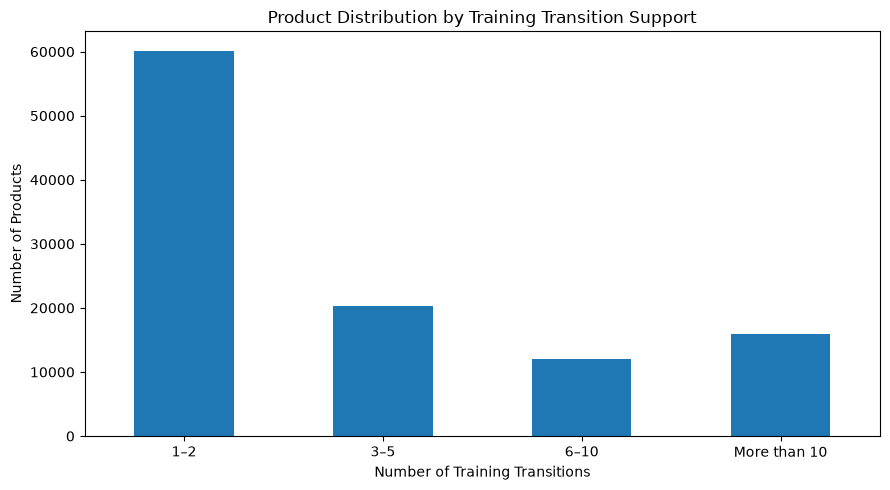

In [185]:
import matplotlib.pyplot as plt
import pandas as pd

support_counts = (
    pd.cut(
        transition_support["training_transitions"],
        bins=[0, 2, 5, 10, float("inf")],
        labels=["1–2", "3–5", "6–10", "More than 10"]
    )
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(9, 5))
support_counts.plot(kind="bar")

plt.title("Product Distribution by Training Transition Support")
plt.xlabel("Number of Training Transitions")
plt.ylabel("Number of Products")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [186]:
support_report = support_counts.rename("product_count").reset_index()
support_report.columns = ["support_group", "product_count"]

support_report["percentage"] = (
    support_report["product_count"]
    / support_report["product_count"].sum()
    * 100
)

print(support_report.round(2))

  support_group  product_count  percentage
0           1–2          60164       55.49
1           3–5          20268       18.69
2          6–10          12030       11.09
3  More than 10          15970       14.73


In [187]:
print("Available model comparison table:", "model_comparison" in globals())
print("Available support summary:", "support_report" in globals())

Available model comparison table: True
Available support summary: True


In [188]:
# Save model comparison results
model_comparison.to_csv(
    "model_comparison_results.csv",
    index=False
)

# Save training support summary
support_report.to_csv(
    "product_transition_support.csv",
    index=False
)

print("Export completed successfully!")
print("1. model_comparison_results.csv")
print("2. product_transition_support.csv")

Export completed successfully!
1. model_comparison_results.csv
2. product_transition_support.csv


In [189]:
import os

for filename in [
    "model_comparison_results.csv",
    "product_transition_support.csv"
]:
    print(filename, "->", os.path.abspath(filename))
    print("Exists:", os.path.exists(filename))

model_comparison_results.csv -> d:\Retailrocket-Product-Intelligence\notebooks\model_comparison_results.csv
Exists: True
product_transition_support.csv -> d:\Retailrocket-Product-Intelligence\notebooks\product_transition_support.csv
Exists: True


In [190]:
# Export the validated hybrid model branch results
hybrid_branch_report = (
    hybrid_evaluation
    .groupby("history_group")
    .agg(
        test_examples=("hit_at_10", "size"),
        hits_at_10=("hit_at_10", "sum"),
        recall_at_10=("hit_at_10", "mean")
    )
    .reset_index()
)

hybrid_branch_report["recall_at_10_pct"] = (
    hybrid_branch_report["recall_at_10"] * 100
)

hybrid_branch_report.to_csv(
    "hybrid_branch_performance.csv",
    index=False
)

print(hybrid_branch_report.round(4))
print("\nCSV exported: hybrid_branch_performance.csv")

              history_group  test_examples  hits_at_10  recall_at_10  \
0       Cold-start fallback          29043         443        0.0153   
1  Known transition history         152664       26754        0.1752   

   recall_at_10_pct  
0            1.5253  
1           17.5248  

CSV exported: hybrid_branch_performance.csv


In [191]:
required_variables = [
    "events",
    "product_metrics",
    "products_500",
    "all_product_funnel"
]

for variable in required_variables:
    print(f"{variable}: {variable in globals()}")

events: True
product_metrics: True
products_500: True
all_product_funnel: True


In [192]:
print("PRODUCT METRICS")
print("Shape:", product_metrics.shape)
print("Columns:", product_metrics.columns.tolist())
display(product_metrics.head())

print("\nALL PRODUCT FUNNEL")
print("Shape:", all_product_funnel.shape)
print("Columns:", all_product_funnel.columns.tolist())
display(all_product_funnel.head())

PRODUCT METRICS
Shape: (235061, 4)
Columns: ['itemid', 'views', 'add_to_cart', 'transactions']


,itemid,views,add_to_cart,transactions
0,3,2,0,0
1,4,3,0,0
2,6,29,0,0
3,9,2,0,0
4,15,18,3,1



ALL PRODUCT FUNNEL
Shape: (147, 6)
Columns: ['itemid', 'sessions_with_view', 'sessions_with_view_then_cart', 'sessions_with_view_cart_then_transaction', 'view_to_cart_rate_pct', 'view_to_transaction_sequence_rate_pct']


,itemid,sessions_with_view,sessions_with_view_then_cart,sessions_with_view_cart_then_transaction,view_to_cart_rate_pct,view_to_transaction_sequence_rate_pct
0,546,423,37,21,8.747045,4.964539
1,869,521,12,7,2.303263,1.343570
2,4001,498,14,8,2.811245,1.606426
3,5411,2153,8,0,0.371575,0.000000
4,5470,423,24,5,5.673759,1.182033


In [193]:
print("Product metrics columns:")
print(product_metrics.columns.tolist())

print("\nTotal views:", int(product_metrics["views"].sum()))
print("Total add-to-cart events:", int(product_metrics["add_to_cart"].sum()))
print("Total transactions:", int(product_metrics["transactions"].sum()))

print("\nProducts with at least 500 views:", len(products_500))
print(
    "Products with at least 500 views and zero carts:",
    int((products_500["add_to_cart"] == 0).sum())
)

Product metrics columns:
['itemid', 'views', 'add_to_cart', 'transactions']

Total views: 2664312
Total add-to-cart events: 69332
Total transactions: 22457

Products with at least 500 views: 147
Products with at least 500 views and zero carts: 31


In [194]:
# Create a separate export; keep the original table unchanged
product_analytics_export = product_metrics.copy()

# Event-level rates
product_analytics_export["cart_rate_per_view_pct"] = (
    product_analytics_export["add_to_cart"]
    .div(product_analytics_export["views"].replace(0, pd.NA))
    .mul(100)
).fillna(0)

product_analytics_export["transaction_rate_per_view_pct"] = (
    product_analytics_export["transactions"]
    .div(product_analytics_export["views"].replace(0, pd.NA))
    .mul(100)
).fillna(0)

# Existing analysis threshold
product_analytics_export["high_view_product"] = (
    product_analytics_export["views"] >= 500
)

# Flag products with at least 500 views and zero cart events
product_analytics_export["high_view_zero_cart"] = (
    (product_analytics_export["views"] >= 500)
    & (product_analytics_export["add_to_cart"] == 0)
)

print("Export table shape:", product_analytics_export.shape)
print(
    "High-view products:",
    int(product_analytics_export["high_view_product"].sum())
)
print(
    "High-view products with zero carts:",
    int(product_analytics_export["high_view_zero_cart"].sum())
)

display(
    product_analytics_export
    .sort_values("views", ascending=False)
    .head(5)
)

C:\Users\HP\AppData\Local\Temp\ipykernel_2004\3416299454.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ).fillna(0)
C:\Users\HP\AppData\Local\Temp\ipykernel_2004\3416299454.py:15: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ).fillna(0)


Export table shape: (235061, 8)
High-view products: 147
High-view products with zero carts: 31


,itemid,views,add_to_cart,transactions,cart_rate_per_view_pct,transaction_rate_per_view_pct,high_view_product,high_view_zero_cart
94720,187946,3410,2,0,0.058651,0.000000,True,False
232496,461686,2539,306,133,12.051989,5.238283,True,False
2719,5411,2325,9,0,0.387097,0.000000,True,False
186716,370653,1854,0,0,0.000000,0.000000,True,True
110536,219512,1740,48,12,2.758621,0.689655,True,False


In [195]:
# Recalculate rates using explicit numeric division
product_analytics_export["cart_rate_per_view_pct"] = (
    product_analytics_export["add_to_cart"]
    .div(product_analytics_export["views"].where(
        product_analytics_export["views"] != 0
    ))
    .fillna(0.0)
    .astype(float)
    .mul(100)
)

product_analytics_export["transaction_rate_per_view_pct"] = (
    product_analytics_export["transactions"]
    .div(product_analytics_export["views"].where(
        product_analytics_export["views"] != 0
    ))
    .fillna(0.0)
    .astype(float)
    .mul(100)
)

print("Missing values in rate columns:")
print(
    product_analytics_export[
        ["cart_rate_per_view_pct", "transaction_rate_per_view_pct"]
    ].isna().sum()
)

print("\nHigh-view products:", int(
    product_analytics_export["high_view_product"].sum()
))
print("High-view zero-cart products:", int(
    product_analytics_export["high_view_zero_cart"].sum()
))

Missing values in rate columns:
cart_rate_per_view_pct           0
transaction_rate_per_view_pct    0
dtype: int64

High-view products: 147
High-view zero-cart products: 31


In [196]:
import os

product_analytics_export.to_csv(
    "product_analytics_metrics.csv",
    index=False
)

export_path = os.path.abspath("product_analytics_metrics.csv")

print("Export successful:", os.path.exists(export_path))
print("File location:", export_path)
print("Rows exported:", len(product_analytics_export))
print("Columns exported:", len(product_analytics_export.columns))

Export successful: True
File location: d:\Retailrocket-Product-Intelligence\notebooks\product_analytics_metrics.csv
Rows exported: 235061
Columns exported: 8


In [197]:
print("Session funnel shape:", all_product_funnel.shape)

print("\nColumns:")
print(all_product_funnel.columns.tolist())

print("\nTop 10 products by view-to-cart sequence rate:")
display(
    all_product_funnel
    .sort_values("view_to_cart_rate_pct", ascending=False)
    .head(10)
)

print("\nBottom 10 products by view-to-cart sequence rate:")
display(
    all_product_funnel
    .sort_values("view_to_cart_rate_pct", ascending=True)
    .head(10)
)

Session funnel shape: (147, 6)

Columns:
['itemid', 'sessions_with_view', 'sessions_with_view_then_cart', 'sessions_with_view_cart_then_transaction', 'view_to_cart_rate_pct', 'view_to_transaction_sequence_rate_pct']

Top 10 products by view-to-cart sequence rate:


,itemid,sessions_with_view,sessions_with_view_then_cart,sessions_with_view_cart_then_transaction,view_to_cart_rate_pct,view_to_transaction_sequence_rate_pct
128,409804,529,127,27,24.007561,5.103970
92,312728,771,132,24,17.120623,3.112840
13,29196,757,102,13,13.474240,1.717305
10,17478,470,63,32,13.404255,6.808511
146,461686,1916,253,85,13.204593,4.436326
130,420960,506,55,33,10.869565,6.521739
69,248455,416,45,27,10.817308,6.490385
16,46232,519,55,13,10.597303,2.504817
77,268883,413,43,20,10.411622,4.842615
17,48030,765,76,32,9.934641,4.183007



Bottom 10 products by view-to-cart sequence rate:


,itemid,sessions_with_view,sessions_with_view_then_cart,sessions_with_view_cart_then_transaction,view_to_cart_rate_pct,view_to_transaction_sequence_rate_pct
12,29100,785,0,0,0.0,0.0
8,15948,653,0,0,0.0,0.0
30,91755,934,0,0,0.0,0.0
31,96924,1434,0,0,0.0,0.0
25,82389,477,0,0,0.0,0.0
44,151444,1150,0,0,0.0,0.0
33,109618,574,0,0,0.0,0.0
62,232509,700,0,0,0.0,0.0
51,187946,3099,0,0,0.0,0.0
55,209994,690,0,0,0.0,0.0


In [198]:
# Export the existing session-based product funnel
all_product_funnel.to_csv(
    "product_session_funnel.csv",
    index=False
)

import os

print(
    "Export successful:",
    os.path.exists("product_session_funnel.csv")
)
print(
    "File location:",
    os.path.abspath("product_session_funnel.csv")
)
print("Products included:", len(all_product_funnel))

Export successful: True
File location: d:\Retailrocket-Product-Intelligence\notebooks\product_session_funnel.csv
Products included: 147


In [199]:
print("Support-level evaluation results available:")

for name in [
    "support_recall_results",
    "support_performance",
    "support_evaluation",
    "support_summary"
]:
    print(f"{name}: {name in globals()}")

Support-level evaluation results available:
support_recall_results: False
support_performance: False
support_evaluation: False
support_summary: False


In [200]:
# Rebuild Recall@10 results by training transition support
support_eval_data = multi_test_data.copy()

support_eval_data["training_transitions"] = (
    support_eval_data["itemid"]
    .map(train_data["itemid"].value_counts())
    .fillna(0)
    .astype(int)
)

support_eval_data["hit_at_10"] = [
    int(actual in recommendations)
    for actual, recommendations in zip(
        support_eval_data["next_view_itemid"].astype(int),
        hybrid_recommendations
    )
]

def assign_support_group(count):
    if count == 0:
        return "No training transitions"
    elif count <= 2:
        return "1–2"
    elif count <= 5:
        return "3–5"
    elif count <= 10:
        return "6–10"
    else:
        return "More than 10"

support_eval_data["support_group"] = (
    support_eval_data["training_transitions"]
    .apply(assign_support_group)
)

support_recall_results = (
    support_eval_data
    .groupby("support_group", as_index=False)
    .agg(
        test_examples=("hit_at_10", "size"),
        hits_at_10=("hit_at_10", "sum"),
        recall_at_10=("hit_at_10", "mean")
    )
)

support_recall_results["recall_at_10_pct"] = (
    support_recall_results["recall_at_10"] * 100
)

display(support_recall_results)

,support_group,test_examples,hits_at_10,recall_at_10,recall_at_10_pct
0,1–2,20720,973,0.046959,4.695946
1,3–5,18970,1679,0.088508,8.850817
2,6–10,21558,3032,0.140644,14.064384
3,More than 10,95090,21119,0.222095,22.209486
4,No training transitions,25369,394,0.015531,1.553077


In [201]:
import os

support_recall_results.to_csv(
    "support_level_recall.csv",
    index=False
)

export_path = os.path.abspath("support_level_recall.csv")

print("Export successful:", os.path.exists(export_path))
print("File location:", export_path)
print("Rows exported:", len(support_recall_results))

Export successful: True
File location: d:\Retailrocket-Product-Intelligence\notebooks\support_level_recall.csv
Rows exported: 5
